# **Comment les profils électriques de la Bretagne et de l'Auvergne-Rhône-Alpes ont-ils évolué entre 2013 et 2024, et dans quelle mesure leurs différences de consommation, de production et de mix énergétique influencent-elles leur couverture des besoins électriques ?**

| Noms | Explication | Dtype |
|---|---|---|
| `Périmètre` | Zone géographique à laquelle correspondent les observations. Dans ton jeu de données, il s’agit de la région étudiée, par exemple **rte_data**. | `str` |
| `datetime` | Date et heure de l’observation. Variable construite à partir des colonnes RTE `Date` et `Heures`. Les données définitives/consolidées sont généralement fournies au pas de **30 minutes**.  | `datetime64[us]` |
| `Consommation` | Puissance électrique consommée sur le territoire au moment considéré, exprimée en **MW**.  | `float64` |
| `Thermique` | Production électrique issue de la filière thermique sur la région, exprimée en **MW**.  | `float64` |
| `Eolien` | Production électrique totale issue de l’énergie éolienne, exprimée en **MW**.  | `float64` |
| `Solaire` | Production électrique issue de l’ensemble des installations photovoltaïques, y compris la production diffuse, exprimée en **MW**. ([RTE][1]) | `float64` |
| `Hydraulique` | Production d’électricité issue de la filière hydraulique, exprimée en **MW**. Elle peut notamment inclure les installations au fil de l’eau, les lacs et le turbinage des STEP selon le niveau de détail disponible. ([RTE][1]) | `float64` |
| `Pompage` | Puissance **consommée** par les stations de transfert d’énergie par pompage (STEP) lorsqu’elles pompent de l’eau vers un réservoir supérieur, exprimée en **MW**. Ce n’est donc pas une production électrique. ([RTE][1]) | `float64` |
| `Bioénergies` | Production électrique provenant des bioénergies, exprimée en **MW**. RTE y regroupe notamment le biogaz, les biocombustibles solides et les déchets. ([RTE][1]) | `float64` |
| `Ech. physiques` | Solde des **flux physiques d’électricité** entrant et sortant de la région sur le réseau RTE, exprimé en **MW**. Il permet notamment d’étudier le caractère importateur ou exportateur d’une région. ([RTE][2]) | `float64` |
| `Eolien terrestre` | Partie de la production éolienne provenant des installations situées **à terre**. Il s’agit d’une décomposition technologique de la variable `Eolien`, exprimée en **MW**. ([RTE][1]) | `float64` |
| `Eolien offshore` | Partie de la production éolienne provenant des installations **en mer (offshore)**, exprimée en **MW**. Il s’agit également d’une composante de la production éolienne totale. ([RTE][1]) | `float64` |

[1]: https://www.rte-france.com/donnees-publications/eco2mix-donnees-temps-reel/production-electricite-par-filiere?utm_source=chatgpt.com "éCO2mix - La production d'électricité par filière | RTE"

[2]: https://www.rte-france.com/donnees-publications/eco2mix-donnees-temps-reel/chiffres-cles-electricite?utm_source=chatgpt.com "éCO2mix - Les chiffres clés de l'électricité en France | RTE"

In [246]:
#---------------------------------------------------------
#                        1. Packages importation 
#---------------------------------------------------------

import pandas as pd 
import seaborn as sns 
from  pathlib import Path 
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
import numpy as np
import os
from matplotlib.ticker import PercentFormatter, FuncFormatter
from matplotlib.patches import Patch

#---------------------------------------------------------
#               2. Project directory initialized
#---------------------------------------------------------

PROJECT_DIR = Path(r"C:\Full_stack\Portfolios\Projets\Data_Analysis_Projects\rte")
os.chdir(PROJECT_DIR)

import src.pipeline as pipeline


#---------------------------------------------------------
#           3. Matplolib Configuration defaults
#---------------------------------------------------------


sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.weight": "normal",
        "axes.titleweight": "bold",
        "axes.labelweight": "normal",
        "font.size": 11,
    }
)

colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}


Mois = {
    1: "Janvier",
    2: "Février",
    3: "Mars",
    4: "Avril",
    5: "Mai",
    6: "Juin",
    7: "Juillet",
    8: "Août",
    9: "Septembre",
    10: "Octobre",
    11: "Novembre",
    12: "Décembre",
}


In [247]:
rte_data = pd.read_parquet(r"data\processed\rte_comparison_2013_2024.parquet")
## A mettre dans Transoformation

prod = [
    "Thermique",
    "Eolien",
    "Solaire",
    "Hydraulique",
    "Bioénergies",
    "Nucléaire"
]
# Calculer la puissance totale (MW) à chaque observation
rte_data["Annee"] = rte_data["datetime"].dt.year
rte_data["Production"] = rte_data[prod].sum(axis=1, min_count=1)

# Agréger par région et par année
production = (
    rte_data.groupby(["Périmètre", "Annee"])
    .agg(Production_totale_MWh=("Production", lambda x: x.sum() * 0.5))
    .reset_index()
)

# Conversion MWh -> GWh
production["Production_totale_GWh"] = production["Production_totale_MWh"] / 1000

# Trier par région et par année
production = production.sort_values(["Périmètre", "Annee"])

# Calculer le taux d'évolution annuel
production["Evolution_%"] = (
    production.groupby("Périmètre")["Production_totale_GWh"]
    .pct_change(fill_method=None)
    .mul(100)
)


## Axe 1 Consomattion électrique

### Q1- Comment la consommation annuelle a-t-elle évolué dans les deux régions entre 2013 et 2024 ?

In [248]:
resume_annuel = (
    rte_data.assign(Annee=rte_data["datetime"].dt.year)
    .groupby(["Annee", "Périmètre"])
    .agg(
        Consommation_Totale=("Consommation", "sum"),
        Consommation_Moyenne=("Consommation", "mean"),
        Consommation_Maximale=("Consommation", "max"),
        Thermique_Total=("Thermique", "sum"),
        Eolien_Total=("Eolien", "sum"),
        Solaire_Total=("Solaire", "sum"),
        Hydraulique_Total=("Hydraulique", "sum"),
        Bioenergies_Total=("Bioénergies", "sum"),
        Nucleaire_Total=("Nucléaire", "sum"),

        Echanges_Physiques_Moyens=("Ech. physiques", "mean"),
        Echanges_Physiques_Totaux=("Ech. physiques", "sum"),
        Eolien_Maximal=("Eolien", "max"),
        Solaire_Maximal=("Solaire", "max"),
    )
)

resume_annuel["Renouvelables_Total"] = (
    resume_annuel["Eolien_Total"]
    + resume_annuel["Solaire_Total"]
    + resume_annuel["Hydraulique_Total"]
    + resume_annuel["Bioenergies_Total"]
)


resume_annuel["Couverture_Renouvelable_%"] = (
    resume_annuel["Renouvelables_Total"] / resume_annuel["Consommation_Totale"] * 100
)

resume_annuel["Part_Nucléaire_%"] = (
    resume_annuel["Nucleaire_Total"] / resume_annuel["Consommation_Totale"] * 100
)


resume_annuel["Part_Thermique_%"] = (
    resume_annuel["Thermique_Total"] / resume_annuel["Consommation_Totale"] * 100
)

resume_annuel["Croissance_Consommation_%"] = (
    resume_annuel.groupby(level="Périmètre")["Consommation_Totale"].pct_change(
        fill_method=None
    )
    * 100
)

resume_annuel["Croissance_Eolien_%"] = (
    resume_annuel.groupby(level="Périmètre")["Eolien_Total"].pct_change(
        fill_method=None
    )
    * 100
)

resume_annuel["Croissance_Solaire_%"] = (
    resume_annuel.groupby(level="Périmètre")["Solaire_Total"].pct_change(
        fill_method=None
    )
    * 100
)

resume_annuel["Echanges_sur_Consommation_%"] = (
    resume_annuel["Echanges_Physiques_Totaux"]
    / resume_annuel["Consommation_Totale"]
    * 100
)

resume_annuel["Consommation_MWh"] = resume_annuel["Consommation_Totale"] * 0.5

energy_columns = [
    "Consommation_Totale",
    "Thermique_Total",
    "Eolien_Total",
    "Solaire_Total",
    "Hydraulique_Total",
    "Bioenergies_Total",
    "Renouvelables_Total",
    "Echanges_Physiques_Totaux",
]

for col in energy_columns:
    resume_annuel[col.replace("_Total", "") + "_GWh"] = resume_annuel[col] * 0.5 / 1000
# Le 0.5 vient du fait que ta granularité est de 30 minutes : une puissance moyenne en MW observée pendant 30 minutes correspond à MW × 0,5 h = MWh.



resume_annuel["Production_Totale"] = (
    resume_annuel["Renouvelables_Total"]
    + resume_annuel["Thermique_Total"]
    + resume_annuel["Nucleaire_Total"]
)

resume_annuel["Couverture_Production_%"] = (
    resume_annuel["Production_Totale"] / resume_annuel["Consommation_Totale"] * 100
)

resume_annuel["Part_Renouvelable_Production_%"] = (
    resume_annuel["Renouvelables_Total"] / resume_annuel["Production_Totale"] * 100
)

In [249]:
col_resume_annuel_prop =resume_annuel.columns[resume_annuel.columns.str.contains("%")]
resume_annuel_prop = resume_annuel[col_resume_annuel_prop]

In [250]:
resume_annuel_prop = round(resume_annuel_prop,1)
# resume_annuel_prop

In [251]:
comparaison = resume_annuel.groupby(level="Périmètre").agg(
    consommation_moyenne=("Consommation_MWh", "mean"),
    consommation_mediane=("Consommation_MWh", "median"),
    consommation_min=("Consommation_MWh", "min"),
    consommation_max=("Consommation_MWh", "max"),
    cons_var=("Consommation_MWh" , 'std'),
)

comparaison = comparaison / 1_000_000  # MWh → TWh


# display(comparaison.round(2))


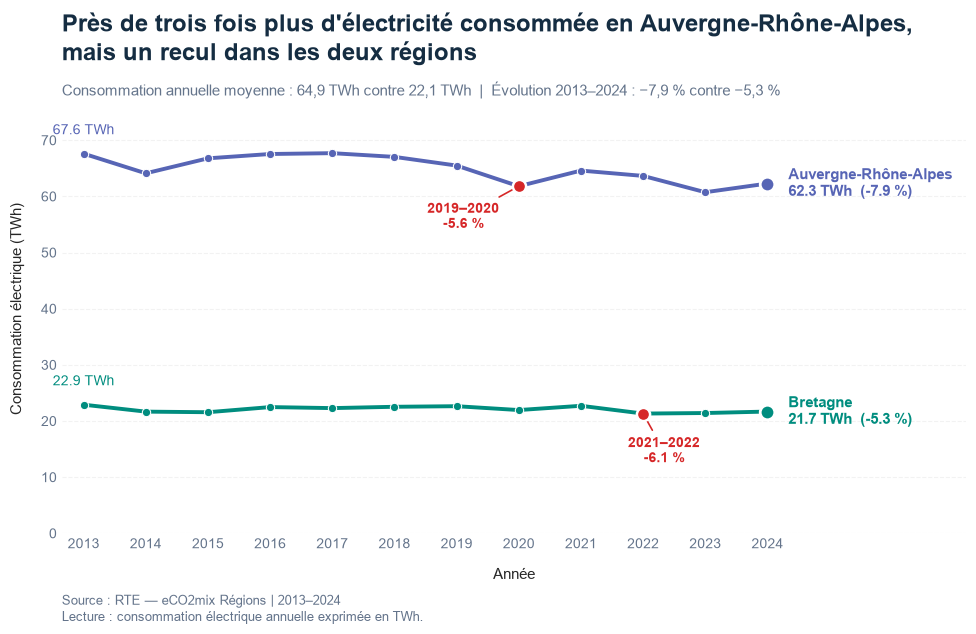

In [252]:
# ============================================================
# 1. PREPARATION
# ============================================================

data = resume_annuel.reset_index().copy()

# Conversion en TWh
data["Consommation_TWh"] = data["Consommation_MWh"] / 1_000_000

data = data.sort_values(["Périmètre", "Annee"])

metric = "Consommation_TWh"


evolution = data.pivot(index="Annee", columns="Périmètre", values=metric)

variation_pct = (evolution.loc[2024] / evolution.loc[2013] - 1) * 100

# ============================================================
# 2. STYLE
# ============================================================

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(13.5, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ============================================================
# 3. COURBES
# ============================================================

sns.lineplot(
    data=data,
    x="Annee",
    y=metric,
    hue="Périmètre",
    hue_order=list(colors),
    palette=colors,
    marker="o",
    markersize=6,
    linewidth=2.8,
    errorbar=None,
    legend=False,
    ax=ax,
)

# ============================================================
# 4. ANNOTATIONS
# ============================================================

for region, color in colors.items():
    start = evolution.loc[2013, region]
    end = evolution.loc[2024, region]
    growth = variation_pct[region]

    # Valeur initiale
    ax.annotate(
        f"{start:.1f} TWh",
        xy=(2013, start),
        xytext=(0, 14),
        textcoords="offset points",
        fontsize=10,
        color=color,
        ha="center",
    )

    # Dernier point
    ax.scatter(
        2024,
        end,
        s=110,
        color=color,
        edgecolor="white",
        linewidth=2,
        zorder=5,
    )

    # Étiquette finale
    ax.annotate(
        f"{region}\n{end:.1f} TWh  ({growth:+.1f} %)",
        xy=(2024, end),
        xytext=(15, 0),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color=color,
        va="center",
        ha="left",
    )

# ============================================================
# 5. TITRE
# ============================================================

fig.text(
    0.09,
    0.965,
    "Près de trois fois plus d'électricité consommée en Auvergne-Rhône-Alpes,\n"
    "mais un recul dans les deux régions",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
    linespacing=1.3,
)

fig.text(
    0.09,
    0.855,
    "Consommation annuelle moyenne : 64,9 TWh contre 22,1 TWh  |  "
    "Évolution 2013–2024 : −7,9 % contre −5,3 %",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

fig.subplots_adjust(top=0.78)
# ============================================================
# 5.1 ANNOTATIONS DES BAISSES IMPORTANTES
# ============================================================

# Données annuelles de consommation
pivot_conso = data.pivot(index="Annee", columns="Périmètre", values="Consommation_TWh")

# Variations annuelles en %
variation_yoy = pivot_conso.pct_change() * 100

# Plus forte baisse par région
worst_drop = variation_yoy.idxmin()
worst_value = variation_yoy.min()

for region in colors.keys():
    drop_year = worst_drop[region]  # année d'arrivée de la baisse
    prev_year = drop_year - 1
    drop_pct = worst_value[region]
    drop_level = pivot_conso.loc[drop_year, region]

    # ajustements visuels selon la région
    if region == "Auvergne-Rhône-Alpes":
        offset = (-40, -30)
    else:
        offset = (15, -35)

    ax.scatter(
        drop_year,
        drop_level,
        s=90,
        color="#D62728",
        edgecolor="white",
        linewidth=1.8,
        zorder=6,
    )

    ax.annotate(
        f"{prev_year}–{drop_year}\n{drop_pct:.1f} %",
        xy=(drop_year, drop_level),
        xytext=offset,
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color="#D62728",
        arrowprops=dict(
            arrowstyle="-",
            color="#D62728",
            lw=1.2,
        ),
        ha="center",
    )

# ============================================================
# 6. AXES
# ============================================================

ax.set_xlabel("Année", fontsize=11, labelpad=12)

ax.set_ylabel(
    "Consommation électrique (TWh)",
    fontsize=11,
    labelpad=12,
)

ax.set_xticks(range(2013, 2025))
ax.set_xlim(2012.65, 2027.2)

# Axe Y à partir de 0 pour comparer les volumes
ax.set_ylim(0, data[metric].max() * 1.18)

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:.0f}"))

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25,
)

ax.grid(axis="x", visible=False)

ax.tick_params(
    axis="both",
    labelsize=10,
    colors="#64748B",
    length=0,
)

sns.despine(ax=ax, left=True, bottom=True)

# ============================================================
# 7. SOURCE
# ============================================================

fig.text(
    0.09,
    0.05,
    "Source : RTE — eCO2mix Régions | 2013–2024",
    fontsize=9,
    color="#64748B",
)

fig.text(
    0.09,
    0.025,
    "Lecture : consommation électrique annuelle exprimée en TWh.",
    fontsize=9,
    color="#64748B",
)

fig.subplots_adjust(
    left=0.09,
    right=0.76,
    top=0.85,
    bottom=0.16,
)

# ============================================================
# 8. EXPORT
# ============================================================

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/01_consommation_electrique_regions.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


In [253]:
comparaison_variabilite = resume_annuel.groupby(level="Périmètre")[
    "Consommation_MWh"
].agg(
    moyenne="mean",
    ecart_type="std",
)

comparaison_variabilite["CV_%"] = (
    comparaison_variabilite["ecart_type"] / comparaison_variabilite["moyenne"] * 100
)

comparaison_variabilite[["CV_%"]].round(2)


,CV_%
Périmètre,
Auvergne-Rhône-Alpes,3.79
Bretagne,2.52


Entre 2013 et 2024, la consommation électrique annuelle moyenne de l'Auvergne-Rhône-Alpes atteint **64,9 TWh**, contre **22,1 TWh** en Bretagne, soit un niveau près de trois fois supérieur.

Sur cette période, les deux régions enregistrent un recul de leur consommation : **−7,9 % en Auvergne-Rhône-Alpes** contre **−5,3 % en Bretagne**.

L'Auvergne-Rhône-Alpes présente également une **variabilité relative plus importante** de sa consommation annuelle, avec un coefficient de variation de **3,79 %**, contre **2,52 %** en Bretagne. Cette différence confirme que les consommations annuelles bretonnes sont relativement plus concentrées autour de leur moyenne sur la période étudiée.

### Q2 Comment la consommation électrique varie-t-elle selon les saisons dans les regions ?

In [254]:
conso_mensuelle = (
    rte_data.assign(Mois=rte_data["datetime"].dt.month)
    .groupby(["Périmètre", "Mois"])
    .agg(Consommation_Moyenne_MW=("Consommation", "mean"))
    .reset_index()
    .sort_values('Mois')
)
# display(conso_mensuelle)

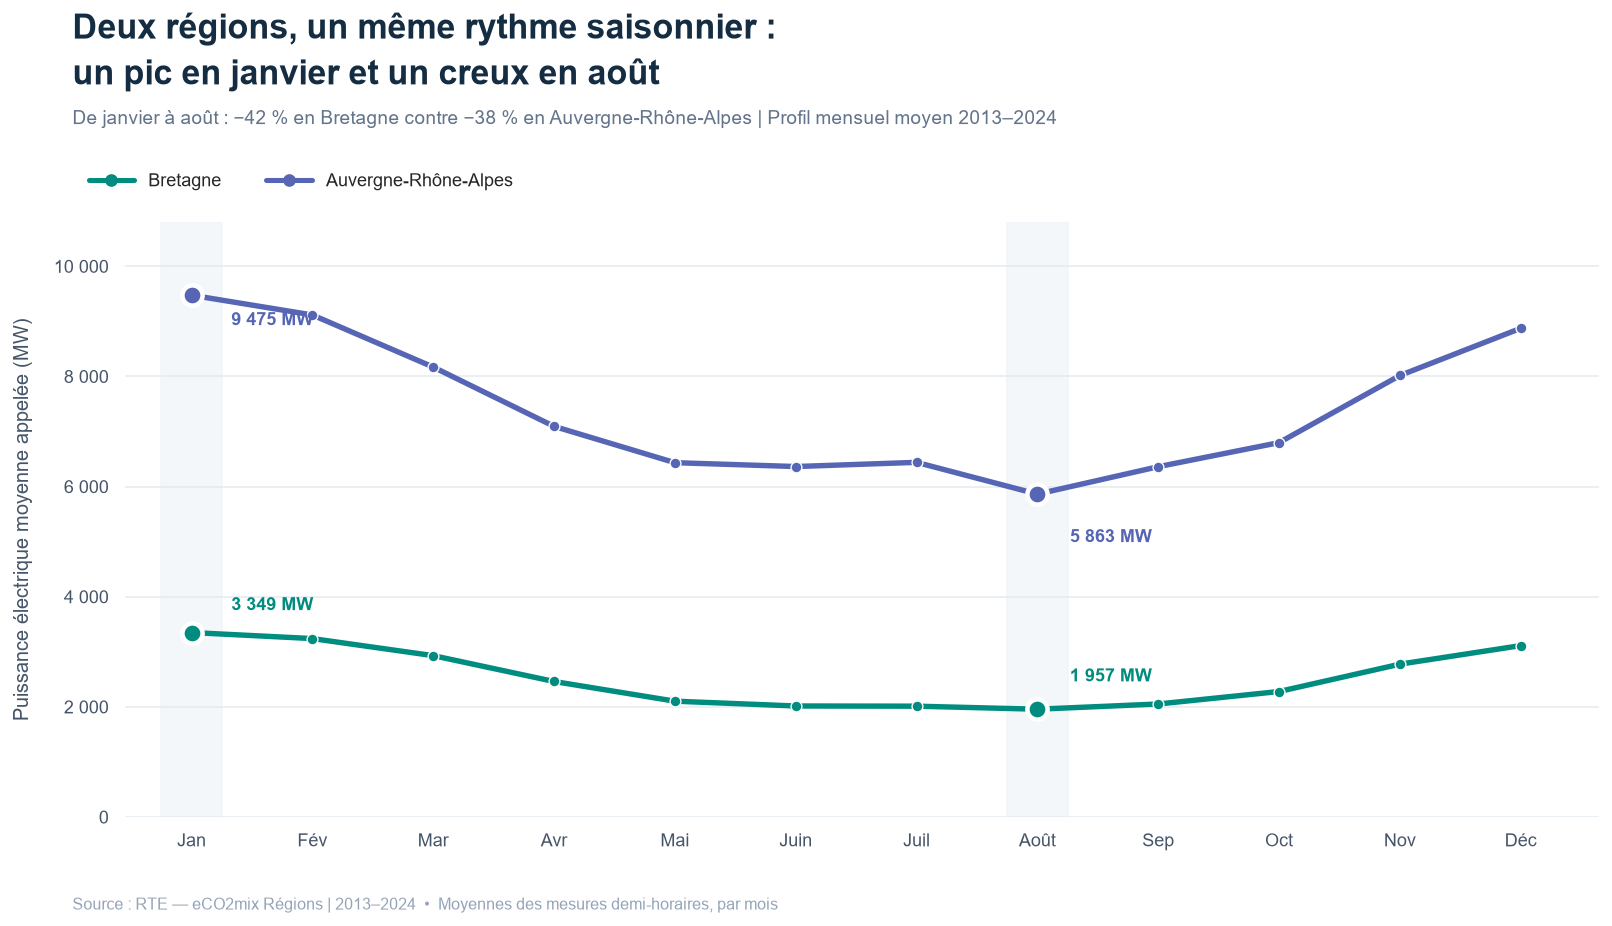

In [255]:

#----------------------------------------------
# 1. CONFIGURATION
# ----------------------------------------------
mois_labels = [
    "Jan",
    "Fév",
    "Mar",
    "Avr",
    "Mai",
    "Juin",
    "Juil",
    "Août",
    "Sep",
    "Oct",
    "Nov",
    "Déc",
]


data = conso_mensuelle.sort_values(["Périmètre", "Mois"]).copy()

sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(figsize=(13.5, 7.5), dpi=130)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ---------------------------------------------
# 2. COURBES
# ---------------------------------------------

sns.lineplot(
    data=data,
    x="Mois",
    y="Consommation_Moyenne_MW",
    hue="Périmètre",
    hue_order=list(colors),
    palette=colors,
    linewidth=3,
    marker="o",
    markersize=6,
    errorbar=None,
    legend=False,
    ax=ax,
    zorder=3,
)

# Repères discrets : janvier et août
ax.axvspan(0.75, 1.25, color="#F1F5F9", alpha=0.8, zorder=0)
ax.axvspan(7.75, 8.25, color="#F1F5F9", alpha=0.8, zorder=0)

# ---------------------------------------------
# 3. ANNOTATIONS MAXIMUM / MINIMUM
# ---------------------------------------------

positions = {
    "Auvergne-Rhône-Alpes": {
        "max": (22, -14),
        "min": (18, -24),
    },
    "Bretagne": {
        "max": (22, 15),
        "min": (18, 18),
    },
}

for region, color in colors.items():
    region_data = data[data["Périmètre"] == region]

    maximum = region_data.loc[region_data["Consommation_Moyenne_MW"].idxmax()]
    minimum = region_data.loc[region_data["Consommation_Moyenne_MW"].idxmin()]

    for type_point, point in [
        ("max", maximum),
        ("min", minimum),
    ]:
        x = point["Mois"]
        y = point["Consommation_Moyenne_MW"]

        ax.scatter(x, y, s=125, color=color, edgecolor="white", linewidth=2.5, zorder=6)

        label = f"{y:,.0f} MW".replace(",", " ")

        ax.annotate(
            label,
            xy=(x, y),
            xytext=positions[region][type_point],
            textcoords="offset points",
            fontsize=10,
            fontweight="bold",
            color=color,
            va="center",
            ha="left",
        )

# ---------------------------------------------
# 4. AXES ET GRILLE
# ---------------------------------------------

ax.set_xlim(0.45, 12.65)
ax.set_ylim(0, 10800)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(mois_labels, fontsize=10.5)

ax.yaxis.set_major_locator(mtick.MultipleLocator(2000))
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", " "))
)

ax.set_xlabel("")
ax.set_ylabel(
    "Puissance électrique moyenne appelée (MW)",
    fontsize=11,
    color="#475569",
    labelpad=12,
)

ax.tick_params(axis="both", labelsize=10, colors="#475569", length=0, pad=9)

ax.grid(
    axis="y",
    color="#E2E8F0",
    linewidth=0.9,
    alpha=0.85,
)
ax.grid(axis="x", visible=False)

ax.set_axisbelow(True)
sns.despine(ax=ax, left=True, bottom=True)

# ---------------------------------------------
# 5. TITRE ET SOUS-TITRE
# ---------------------------------------------

fig.text(
    0.08,
    0.965,
    "Deux régions, un même rythme saisonnier :",
    fontsize=19,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.08,
    0.918,
    "un pic en janvier et un creux en août",
    fontsize=19,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.08,
    0.865,
    "De janvier à août : −42 % en Bretagne contre −38 % "
    "en Auvergne-Rhône-Alpes | Profil mensuel moyen 2013–2024",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# ---------------------------------------------
# 6. LÉGENDE PERSONNALISÉE
# ---------------------------------------------


handles = [
    Line2D(
        [0],
        [0],
        color=color,
        marker="o",
        markersize=6,
        linewidth=2.8,
        label=region,
    )
    for region, color in colors.items()
]

fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.08, 0.817),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.5,
    columnspacing=2.5,
)

# ---------------------------------------------
# 7. SOURCE ET EXPORT
# ---------------------------------------------

fig.text(
    0.08,
    0.045,
    "Source : RTE — eCO2mix Régions | 2013–2024"
    "  •  Moyennes des mesures demi-horaires, par mois",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.11,
    right=0.95,
    top=0.75,
    bottom=0.14,
)

# Décommenter pour exporter
fig.savefig(
    "figures/02_consommation_saisonnalite.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


Malgré des niveaux de consommation trés differents , la **Bretagne** et **l'Auvergne-Rhône-Alpes** présentent un profil saisonnier comparable , avec un maximun en janvier et un minimun en août.

Toutefois , la **consommation moyenne diminue** de 41.6 %(3 612 MW) entre janvier et août en **Bretagne**  contre 38.1% (1 392 MW) en **Auvergne-Rhône-Alpes**.  

La **Brétagne** présente donc un contraste relatif entre ces deux mois légérement prononcé , alors que **L'Auvergne-Rhône** enregistre une baisse plus importante

Ces résultats suggérent des différences dans l'intensité saisonnière de la demande électrique  , dont les facteurs restent à examiner.

### Q3. Comment les pics de demande électrique se distinguent-ils entre les deux régions ?	Analyse des puissances maximales, éventuellement par saison ou année 

In [256]:
conso_pics = (
    rte_data.assign(
        Mois=rte_data["datetime"].dt.month, Heure=rte_data["datetime"].dt.hour
    )
    .groupby(["Périmètre", "Mois", "Heure"])
    .agg(Consommation_P95_MW=("Consommation", lambda x: x.quantile(0.95)))
    .reset_index()
)

conso_moyenne_bretagne = rte_data.loc[rte_data['Périmètre'] == "Bretagne" , "Consommation"].mean()
conso_moyenne_auvergne = rte_data.loc[ rte_data["Périmètre"] != "Bretagne", "Consommation"].mean()

conso_pics_bretagne = conso_pics.loc[conso_pics["Périmètre"] == "Bretagne"].copy()

conso_pics_auvergne = conso_pics.loc[
    conso_pics["Périmètre"] == "Auvergne-Rhône-Alpes"
].copy()

conso_pics_bretagne["Indice_P95"] = (
    100 * conso_pics_bretagne["Consommation_P95_MW"] / conso_moyenne_bretagne
)

conso_pics_auvergne["Indice_P95"] = (
    100 * conso_pics_auvergne["Consommation_P95_MW"] / conso_moyenne_auvergne
)

In [257]:
heatmap_bretagne = conso_pics_bretagne.pivot(
    index="Mois", columns="Heure", values="Indice_P95"
)
heatmap_auvergne = conso_pics_auvergne.pivot(
    index="Mois", columns="Heure", values="Indice_P95"
)

heatmap_bretagne  = heatmap_bretagne.astype("float64")
heatmap_auvergne  = heatmap_auvergne.astype("float64")



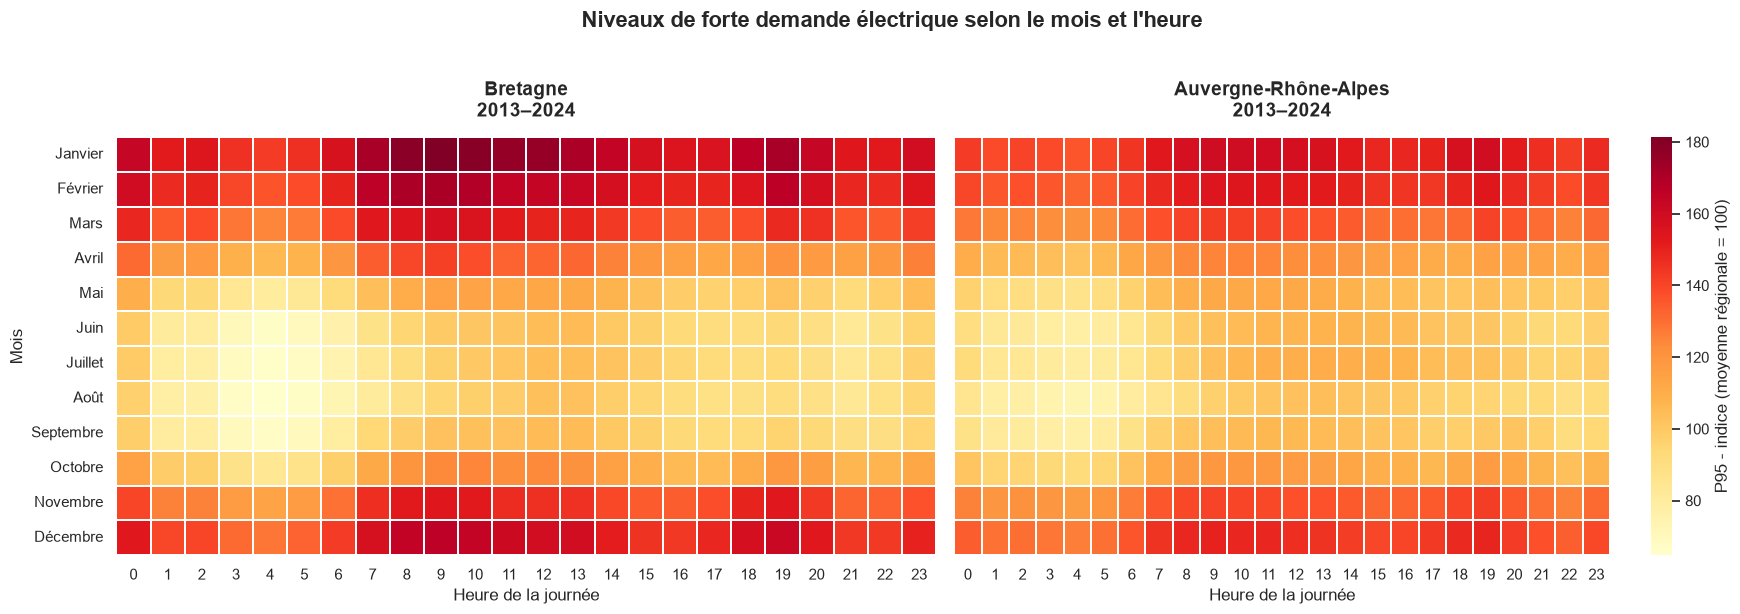

In [258]:


# Même échelle de couleur pour comparer les deux régions
vmin = min(heatmap_bretagne.min().min(), heatmap_auvergne.min().min())
vmax = max(heatmap_bretagne.max().max(), heatmap_auvergne.max().max())

fig, ax = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# Bretagne
sns.heatmap(
    heatmap_bretagne,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="white",
    vmin=vmin,
    vmax=vmax,
    cbar=False,
    ax=ax[0],
)

ax[0].set_title(
    "Bretagne\n2013–2024",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax[0].set_xlabel("Heure de la journée")
ax[0].set_ylabel("Mois")
ax[0].set_yticklabels(list(Mois.values()), rotation=0)

# Auvergne-Rhône-Alpes
sns.heatmap(
    heatmap_auvergne,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="white",
    vmin=vmin,
    vmax=vmax,
    cbar=True,
    cbar_kws={"label": "P95 - indice (moyenne régionale = 100)"},
    ax=ax[1],
)

ax[1].set_title(
    "Auvergne-Rhône-Alpes\n2013–2024",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax[1].set_xlabel("Heure de la journée")
ax[1].set_ylabel("")
ax[1].set_yticklabels(list(Mois.values()), rotation=0)

# Titre global
fig.suptitle(
    "Niveaux de forte demande électrique selon le mois et l'heure",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()
plt.show()


L'analyse des profils de consommation hivernaux révèle une **pointe matinale relativement plus prononcée en Bretagne** qu'en Auvergne-Rhône-Alpes, sur la plage horaire de 7 h à 11 h.

Cette différence, estimée à **2,58 points d'indice en moyenne sur les journées étudiées**, se retrouve sur l'ensemble des hivers complets de 2014 à 2024. Elle suggère une caractéristique persistante du profil journalier breton, malgré des niveaux de consommation absolus nettement inférieurs à ceux de l'Auvergne-Rhône-Alpes.

## **Axe 2 — Production électrique et mix énergétique**
Objectif : comprendre comment chaque région produit son électricité et quelles filières dominent.

Question	Analyse / Visualisation

### **Q4.1 Comment la production électrique totale a-t-elle évolué entre 2013 et 2024 ?**	

In [259]:
resume_annuel = resume_annuel.reset_index() 

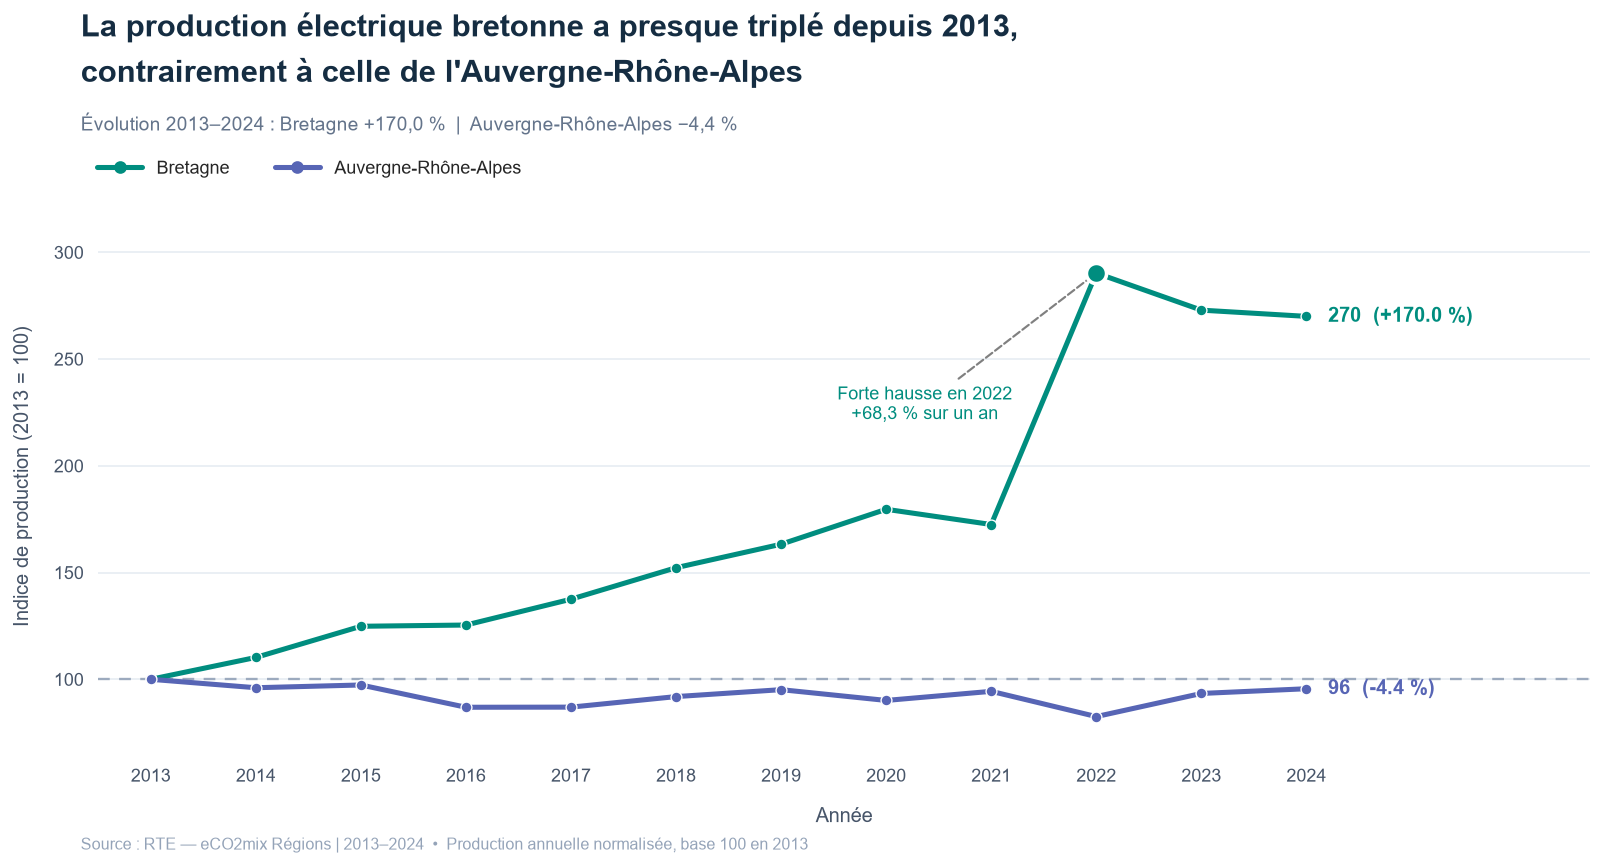

In [260]:

# ─────────────────────────────────────────────
# 1. PRÉPARATION DES DONNÉES
# ─────────────────────────────────────────────

colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}

resume_annuel["Production_TWh"] = resume_annuel["Production_Totale"] * 0.5 / 1_000_000

# Tri indispensable pour la référence 2013
production = resume_annuel.reset_index().sort_values(["Périmètre", "Annee"]).copy()

production["Indice_Production"] = (
    production["Production_TWh"]
    / production.groupby("Périmètre")["Production_TWh"].transform("first")
    * 100
)

# ─────────────────────────────────────────────
# 2. CONFIGURATION
# ─────────────────────────────────────────────

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(13.5, 7), dpi=130)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ─────────────────────────────────────────────
# 3. COURBES
# ─────────────────────────────────────────────

sns.lineplot(
    data=production,
    x="Annee",
    y="Indice_Production",
    hue="Périmètre",
    hue_order=list(colors),
    palette=colors,
    marker="o",
    markersize=6,
    linewidth=2.8,
    errorbar=None,
    legend=False,
    ax=ax,
    zorder=3,
)

# Ligne de référence 2013 = 100
ax.axhline(
    100,
    color="#94A3B8",
    linestyle=(0, (5, 4)),
    linewidth=1.3,
    alpha=0.9,
    zorder=1,
)

# ─────────────────────────────────────────────
# 4. ANNOTATIONS
# ─────────────────────────────────────────────

for region, color in colors.items():
    data_region = production.loc[production["Périmètre"] == region]

    debut = data_region.loc[data_region["Annee"] == 2013].iloc[0]

    fin = data_region.loc[data_region["Annee"] == 2024].iloc[0]

    variation = fin["Indice_Production"] - 100

    ax.annotate(
        f"{fin['Indice_Production']:.0f}  ({variation:+.1f} %)",
        xy=(2024, fin["Indice_Production"]),
        xytext=(12, 0),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color=color,
        va="center",
        ha="left",
    )

# Mise en évidence du bond breton de 2022
point_2022 = production.loc[
    (production["Périmètre"] == "Bretagne") & (production["Annee"] == 2022)
].iloc[0]

ax.scatter(
    2022,
    point_2022["Indice_Production"],
    s=125,
    color=colors["Bretagne"],
    edgecolor="white",
    linewidth=2,
    zorder=6,
)

ax.annotate(
    "Forte hausse en 2022\n+68,3 % sur un an",
    xy=(2022, point_2022["Indice_Production"]),
    xytext=(-95, -62),
    textcoords="offset points",
    fontsize=10,
    fontweight="medium",
    color=colors["Bretagne"],
    arrowprops=dict(
        arrowstyle="-",
        color='gray',
        linewidth=1.2,
        linestyle='--'
    ),
    ha="center",
    va="top",
)

# ─────────────────────────────────────────────
# 5. AXES ET GRILLE
# ─────────────────────────────────────────────

ax.set_xlim(2012.5, 2026.7)
ax.set_ylim(65, 325)

ax.set_xticks(range(2013, 2025))
ax.set_xlabel("Année", fontsize=11, color="#475569", labelpad=12)

ax.set_ylabel(
    "Indice de production (2013 = 100)",
    fontsize=11,
    color="#475569",
    labelpad=12,
)

ax.yaxis.set_major_locator(mtick.MultipleLocator(50))

ax.tick_params(
    axis="both",
    labelsize=10,
    colors="#475569",
    length=0,
    pad=8,
)

ax.grid(
    axis="y",
    color="#E2E8F0",
    linewidth=0.9,
    alpha=0.85,
)

ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

sns.despine(ax=ax, left=True, bottom=True)

# ─────────────────────────────────────────────
# 6. TITRE ET SOUS-TITRE
# ─────────────────────────────────────────────

fig.text(
    0.09,
    0.965,
    "La production électrique bretonne a presque triplé depuis 2013,",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.915,
    "contrairement à celle de l'Auvergne-Rhône-Alpes",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.855,
    "Évolution 2013–2024 : Bretagne +170,0 %  |  Auvergne-Rhône-Alpes −4,4 %",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# ─────────────────────────────────────────────
# 7. LÉGENDE
# ─────────────────────────────────────────────

from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0],
        [0],
        color=color,
        marker="o",
        linewidth=2.8,
        markersize=6,
        label=region,
    )
    for region, color in colors.items()
]

fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.09, 0.82),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.5,
    columnspacing=2.5,
)

# ─────────────────────────────────────────────
# 8. SOURCE ET EXPORT
# ─────────────────────────────────────────────

fig.text(
    0.09,
    0.045,
    "Source : RTE — eCO2mix Régions | 2013–2024  •  "
    "Production annuelle normalisée, base 100 en 2013",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.10,
    right=0.95,
    top=0.76,
    bottom=0.15,
)

fig.savefig(
    "figures/04_evolution_production_electrique.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

Entre 2013 et 2024, les deux régions présentent des trajectoires de production électrique nettement différentes.

**En Bretagne, la production augmente de 170 % sur la période**, passant de 2,51 à 6,78 TWh. Cette progression est notamment marquée par une forte accélération entre 2021 et 2022 (**+68,28 %**), suivie d'un léger recul les années suivantes.

À l'inverse, **l'Auvergne-Rhône-Alpes enregistre une diminution globale limitée de 4,4 %**, malgré plusieurs fluctuations annuelles et un recul particulièrement marqué en 2022.

Toutefois, la croissance bretonne ne remet pas en cause les différences d'échelle entre les deux régions : **en 2024, l'Auvergne-Rhône-Alpes produit 119,3 TWh contre 6,78 TWh en Bretagne, soit environ 17,6 fois plus**.

### **Q4.2. Quelles filiéres expliquent la forte hausse de production en Bretagne en 2022 ?**

In [261]:
# Filtrage : Bretagne, 2021 et 2022
bretagne_df = rte_data.query("Annee in [2021, 2022] and Périmètre == 'Bretagne'")

prod = [
    "Thermique",
    "Eolien",
    "Solaire",
    "Hydraulique",
    "Bioénergies",
]

# Production annuelle en TWh
resume_brg = bretagne_df.groupby("Annee")[prod].sum().mul(0.5 / 1_000_000).T.copy()

# Variations absolues
resume_brg["Variation (TWh)"] = resume_brg[2022] - resume_brg[2021]

# Variations relatives
resume_brg["Variation (%)"] = (
    resume_brg["Variation (TWh)"] / resume_brg[2021].replace(0, float("nan")) * 100
)

# Contribution à la variation totale
variation_totale = resume_brg["Variation (TWh)"].sum()

resume_brg["Contribution à la hausse (%)"] = (
    resume_brg["Variation (TWh)"] / variation_totale * 100
)

# Parts dans la production de chaque année
resume_brg["Part 2021 (%)"] = resume_brg[2021] / resume_brg[2021].sum() * 100

resume_brg["Part 2022 (%)"] = resume_brg[2022] / resume_brg[2022].sum() * 100

display(resume_brg.round(3))


Annee,2021,2022,Variation (TWh),Variation (%),Contribution à la hausse (%),Part 2021 (%),Part 2022 (%)
Thermique,1.049,3.78,2.731,260.323,92.327,24.217,51.853
Eolien,1.945,2.034,0.089,4.554,2.994,44.894,27.893
Solaire,0.285,0.421,0.136,47.799,4.599,6.569,5.77
Hydraulique,0.603,0.592,-0.011,-1.871,-0.382,13.923,8.119
Bioénergies,0.45,0.464,0.014,3.032,0.462,10.397,6.366


In [262]:
# Verification 1
print("Production 2021 :", round(resume_brg[2021].sum(), 3), "TWh")
print("Production 2022 :", round(resume_brg[2022].sum(), 3), "TWh")

print("Augmentation totale :", round(resume_brg["Variation (TWh)"].sum(), 3), "TWh")

print(
    "Somme des contributions :",
    round(resume_brg["Contribution à la hausse (%)"].sum(), 2),
    "%",
)

## Verification 2 


thermique_mensuel = (
    bretagne_df.assign(mois=lambda df: df["datetime"].dt.month)
    .groupby(["Annee", "mois"])["Thermique"]
    .sum()
    .reset_index()
)

# Production thermique recalculée à partir des mois
controle = thermique_mensuel.groupby("Annee")["Thermique"].sum().mul(0.5 / 1_000_000)

# Production thermique calculée directement par année
reference = resume_brg.loc["Thermique", [2021, 2022]]

# Comparaison
verification = pd.DataFrame(
    {
        "Production_annuelle_TWh": reference,
        "Production_depuis_mois_TWh": controle,
    }
)

verification["Ecart_TWh"] = (
    verification["Production_annuelle_TWh"] - verification["Production_depuis_mois_TWh"]
)

display(verification)

assert np.allclose(
    verification["Production_annuelle_TWh"].to_numpy(dtype=float),
    verification["Production_depuis_mois_TWh"].to_numpy(dtype=float),
), "Incohérence entre les agrégations mensuelle et annuelle"

Production 2021 : 4.332 TWh
Production 2022 : 7.291 TWh
Augmentation totale : 2.958 TWh
Somme des contributions : 100.0 %


,Production_annuelle_TWh,Production_depuis_mois_TWh,Ecart_TWh
Annee,,,
2021,1.049175,1.049175,0.0
2022,3.780417,3.780417,0.0


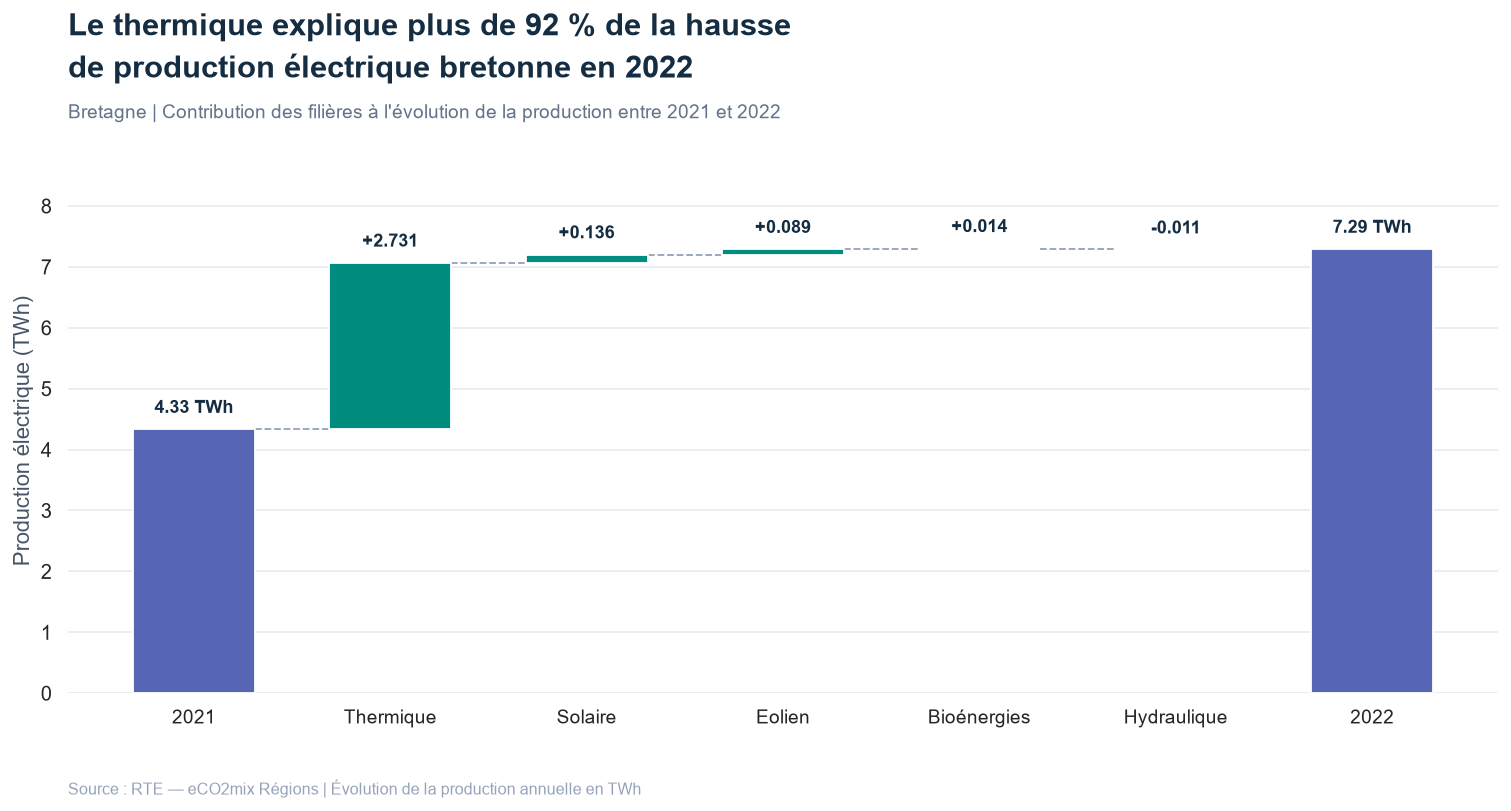

In [263]:
import numpy as np

# 1. Données
variations = resume_brg["Variation (TWh)"].sort_values(ascending=False)
total_2021 = resume_brg[2021].sum()
total_2022 = resume_brg[2022].sum()

labels = ["2021"] + variations.index.tolist() + ["2022"]
values = [total_2021] + variations.tolist() + [total_2022]

# Positions verticales des barres
bottoms = [0]
niveau = total_2021

for variation in variations:
    bottoms.append(min(niveau, niveau + variation))
    niveau += variation

bottoms.append(0)

# Couleurs : valeurs totales, hausses, baisses
bar_colors = (
    ["#5765B5"] + ["#008D7F" if v >= 0 else "#D65A62" for v in variations] + ["#5765B5"]
)

# 2. Figure
fig, ax = plt.subplots(figsize=(12.5, 6.5), dpi=130)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

x = np.arange(len(labels))

ax.bar(x, values, bottom=bottoms, color=bar_colors, width=0.62, zorder=3)

# 3. Connecteurs
niveau = total_2021

for i, variation in enumerate(variations):
    ax.plot(
        [i + 0.31, i + 0.69],
        [niveau, niveau],
        color="#94A3B8",
        linewidth=1,
        linestyle="--",
        zorder=2,
    )
    niveau += variation

# 4. Labels des barres
for i, (valeur, base) in enumerate(zip(values, bottoms)):
    if i == 0 or i == len(values) - 1:
        texte = f"{valeur:.2f} TWh"
    else:
        texte = f"{valeur:+.3f}"

    ax.annotate(
        texte,
        xy=(i, base + valeur),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#152D42",
    )

# 5. Mise en page
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10.5)
ax.set_ylabel("Production électrique (TWh)", color="#475569")
ax.set_ylim(0, total_2022 * 1.18)

ax.yaxis.set_major_locator(mtick.MultipleLocator(1))
ax.grid(axis="y", color="#E2E8F0", alpha=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=9)

for spine in ax.spines.values():
    spine.set_visible(False)

# 6. Storytelling
fig.text(
    0.09,
    0.965,
    "Le thermique explique plus de 92 % de la hausse",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.917,
    "de production électrique bretonne en 2022",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.857,
    "Bretagne | Contribution des filières à l'évolution "
    "de la production entre 2021 et 2022",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

fig.text(
    0.09,
    0.04,
    "Source : RTE — eCO2mix Régions | Évolution de la production annuelle en TWh",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(left=0.09, right=0.97, top=0.78, bottom=0.16)

fig.savefig(
    "figures/04_1_evolution_production_electrique_2021_2022.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


La forte hausse de la production électrique bretonne entre 2021 et 2022 (**+68,3 %**) s'explique principalement par l'augmentation de la production thermique.

Cette filière progresse de **2,73 TWh (+260,3 %)** et représente à elle seule **92,3 % de l'augmentation nette** de la production régionale. Sa part dans le mix électrique passe ainsi de **24,2 % à 51,9 %**, devenant majoritaire en 2022.

Les contributions du solaire (+0,14 TWh) et de l'éolien (+0,09 TWh) restent nettement plus modestes. La croissance de la production totale en 2022 ne traduit donc pas principalement une accélération de la production renouvelable, mais une hausse exceptionnelle de la production thermique.

L'analyse mensuelle confirme que la forte hausse de production thermique bretonne en 2022 ne résulte pas uniquement de quelques épisodes hivernaux. Alors qu'en 2021 la production thermique était particulièrement faible du printemps à la fin de l'été, elle demeure élevée durant l'ensemble de l'année 2022.

Ce changement de profil contribue à expliquer l'augmentation exceptionnelle de la production thermique annuelle, qui représente plus de **92 % de la hausse totale de production électrique bretonne** entre 2021 et 2022.

### **Q5. Comparaison des mix électriques régionaux**

In [264]:
filiere_colors = {
    "Nucléaire": "#7C3AED",
    "Thermique": "#E76F51",
    "Eolien": "#3B82F6",
    "Solaire": "#F4B942",
    "Hydraulique": "#0891B2",
    "Bioénergies": "#2A9D65",
}

prod = list(filiere_colors.keys())

resume_prod = (
rte_data.groupby(['Périmètre' , 'Annee'])[prod]
.agg(
    lambda x :x.sum()
)
.reset_index()
)

bretagne_part_prod = (
    resume_prod
    .query("Périmètre == 'Bretagne'")
    .drop("Périmètre", axis=1)
    .set_index("Annee")
)
auvergne_part_prod = (
    resume_prod
        .query("Périmètre != 'Bretagne'")
        .drop("Périmètre", axis=1)
        .set_index("Annee")
        .sort_index()
)
bretagne_part_prod = (
    bretagne_part_prod
    .div(bretagne_part_prod.sum(axis=1), axis=0)
    .mul(100)
)

auvergne_part_prod = auvergne_part_prod.div(auvergne_part_prod.sum(axis=1), axis=0).mul(
    100
)

display(bretagne_part_prod.loc[[2013, 2024]].round(2))
display(auvergne_part_prod.loc[[2013, 2024]].round(2))



assert np.allclose(bretagne_part_prod.sum(axis=1).to_numpy(dtype=float), 100)

assert np.allclose(auvergne_part_prod.sum(axis=1).to_numpy(dtype=float), 100)

,Nucléaire,Thermique,Eolien,Solaire,Hydraulique,Bioénergies
Annee,,,,,,
2013,0.0,10.26,55.8,6.0,20.31,7.63
2024,0.0,23.99,50.59,9.84,8.68,6.89


,Nucléaire,Thermique,Eolien,Solaire,Hydraulique,Bioénergies
Annee,,,,,,
2013,71.21,1.04,0.59,0.38,26.33,0.45
2024,67.22,0.87,1.25,2.43,27.39,0.85


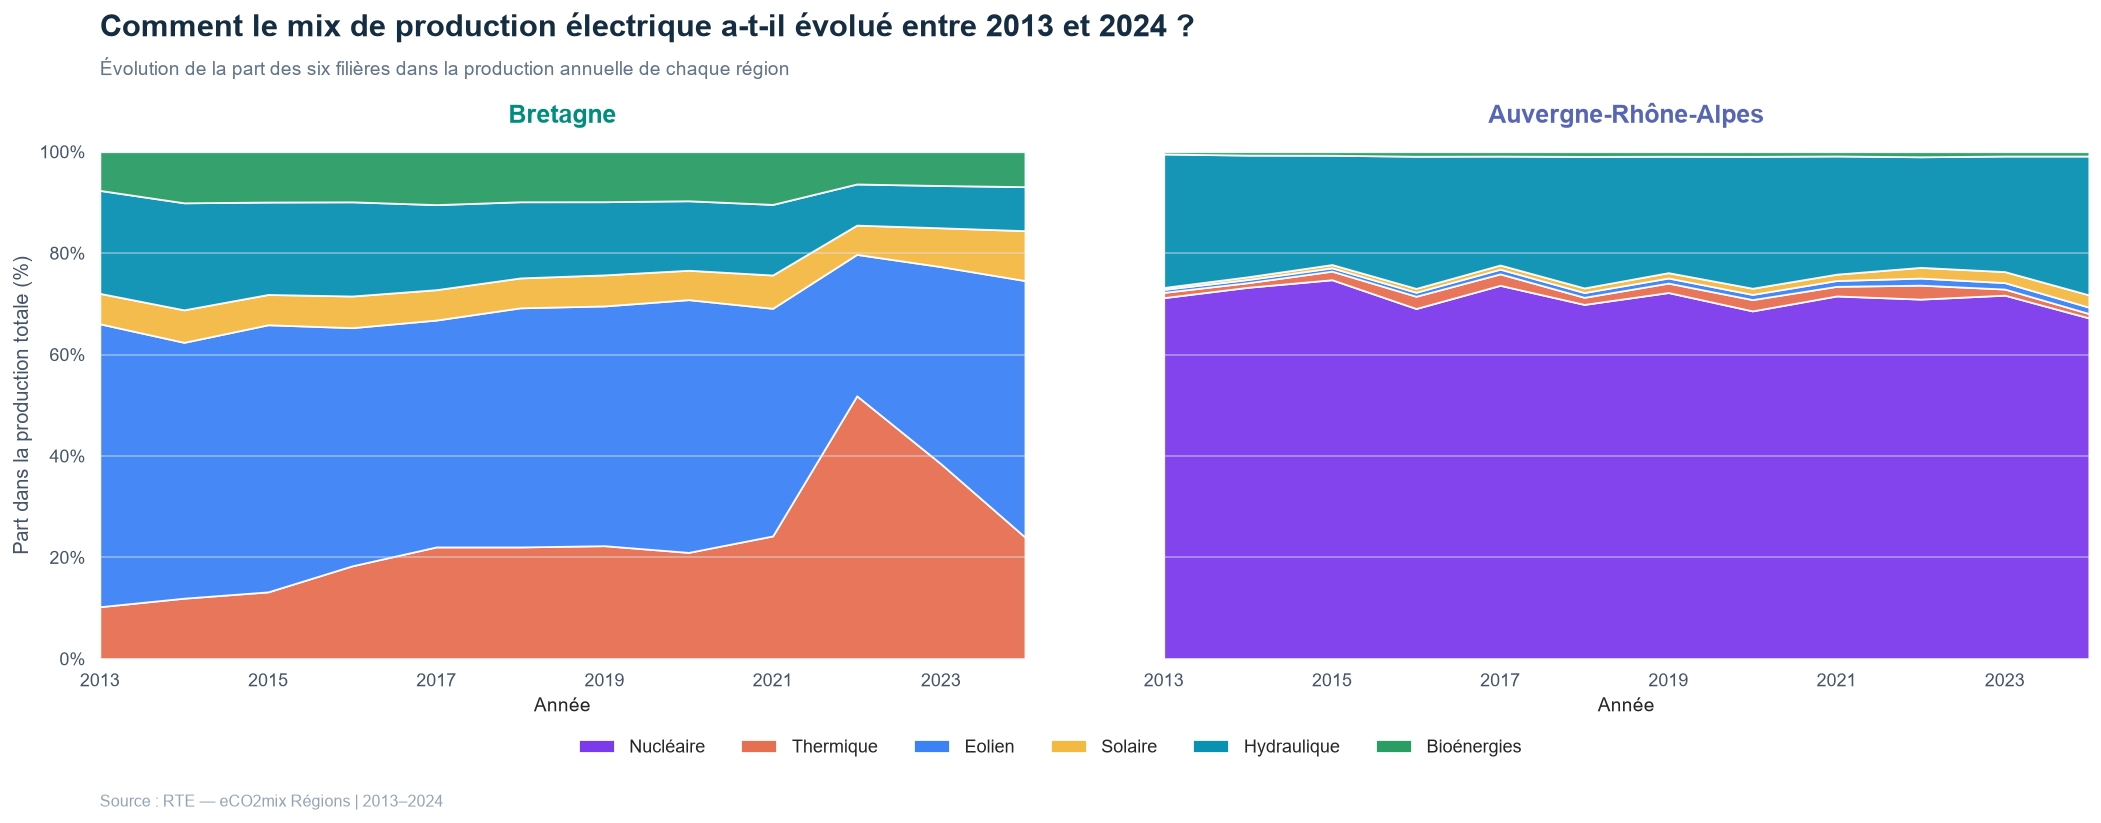

In [265]:


filieres = list(filiere_colors)

fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), sharex=True, sharey=True, dpi=130)

fig.patch.set_facecolor("white")

regions = [
    ("Bretagne", bretagne_part_prod, "#008D7F"),
    ("Auvergne-Rhône-Alpes", auvergne_part_prod, "#5765B5"),
]

for a, (region, df, region_color) in zip(ax, regions):
    df = df.sort_index()

    a.stackplot(
        df.index,
        *[df[col].to_numpy(dtype=float) for col in filieres],
        colors=[filiere_colors[col] for col in filieres],
        alpha=0.95,
    )

    a.set_title(
        region,
        fontsize=14,
        fontweight="bold",
        color=region_color,
        pad=16,
    )

    a.set_xlim(2013, 2024)
    a.set_ylim(0, 100)

    a.set_xticks(range(2013, 2025, 2))
    a.set_xlabel("Année", fontsize=10.5)

    a.yaxis.set_major_formatter(PercentFormatter(100))

    a.grid(axis="y", color="#E2E8F0", alpha=0.45)
    a.set_axisbelow(False)

    a.tick_params(
        axis="both",
        labelsize=10,
        colors="#475569",
        length=0,
        pad=8,
    )

    sns.despine(ax=a, left=True, bottom=True)

ax[0].set_ylabel(
    "Part dans la production totale (%)",
    fontsize=11,
    color="#475569",
)

# Titre provisoire, à améliorer après analyse
fig.text(
    0.07,
    0.965,
    "Comment le mix de production électrique a-t-il évolué entre 2013 et 2024 ?",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.07,
    0.912,
    "Évolution de la part des six filières dans la production annuelle de chaque région",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# Légende commune
handles = [Patch(facecolor=filiere_colors[f], label=f) for f in filieres]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.065),
    ncol=6,
    frameon=False,
    fontsize=10,
)

fig.text(
    0.07,
    0.025,
    "Source : RTE — eCO2mix Régions | 2013–2024",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.80,
    bottom=0.20,
    wspace=0.15,
)

fig.savefig(
    "figures/05_mix_production_electrique.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()


In [266]:
resume_global = rte_data.groupby("Périmètre")[prod + ["Production"]].sum()

parts_globales = resume_global[prod].div(resume_global["Production"], axis=0).mul(100)

assert np.allclose(
    resume_global[prod].sum(axis=1).to_numpy(dtype=float),
    resume_global["Production"].to_numpy(dtype=float),
) # Verification du calcul 
parts_globales

,Nucléaire,Thermique,Eolien,Solaire,Hydraulique,Bioénergies
Périmètre,,,,,,
Auvergne-Rhône-Alpes,71.191087,1.68465,0.962661,1.178375,24.167723,0.815505
Bretagne,0.0,26.814757,44.659474,6.742484,13.224688,8.558598


Sur la période 2013–2024, les deux régions présentent des mix de production électrique structurellement différents.

En Auvergne-Rhône-Alpes, la production cumulée repose principalement sur le **nucléaire (71,19 %) et l'hydraulique (24,17 %)**, qui représentent ensemble **95,36 %** de l'électricité produite.

En Bretagne, le mix est davantage réparti entre plusieurs filières, dominées par **l'éolien (44,66 %) et le thermique (26,81 %)**. L'évolution annuelle révèle toutefois une modification ponctuelle importante en 2022, lorsque le thermique devient majoritaire dans la production bretonne.

Ces résultats mettent en évidence une forte concentration de la production autour du nucléaire et de l'hydraulique en Auvergne-Rhône-Alpes, contre une composition plus diversifiée et davantage variable en Bretagne.

## **Axe 3. Transition vers les énergies renouvelables**



### **Q6.  Comment la production d'électricité renouvelable a-t-elle évolué dans les deux régions entre 2013 et 2024 ?**

In [267]:
filieres = {
    "Eolien_Total": "Eolien",
    "Solaire_Total": "Solaire",
    "Hydraulique_Total": "Hydraulique",
    "Bioenergies_Total": "Bioénergies"}


renouvelable_df = (
    resume_annuel.reset_index()
    .loc[lambda df: df["Annee"].isin([2013, 2024])][["Annee", "Périmètre", *filieres]]
    .rename(columns=filieres)
    .melt(id_vars=["Annee", "Périmètre"], var_name="Filière", value_name="Production")
)

# Les colonnes *_Total sont des sommes de mesures en MW
renouvelable_df["Production_TWh"] = renouvelable_df["Production"] * 0.5 / 1_000_000

# 2013 et 2024 dans des colonnes distinctes
renouvelable_df = renouvelable_df.pivot(
    index=["Périmètre", "Filière"], columns="Annee", values="Production_TWh"
).reset_index()

# Variation absolue en TWh
renouvelable_df["Variation_TWh"] = renouvelable_df[2024] - renouvelable_df[2013]

# Croissance relative depuis 2013
renouvelable_df["Croissance_%"] = (
    renouvelable_df["Variation_TWh"]
    / renouvelable_df[2013].replace(0, float("nan"))
    * 100
)




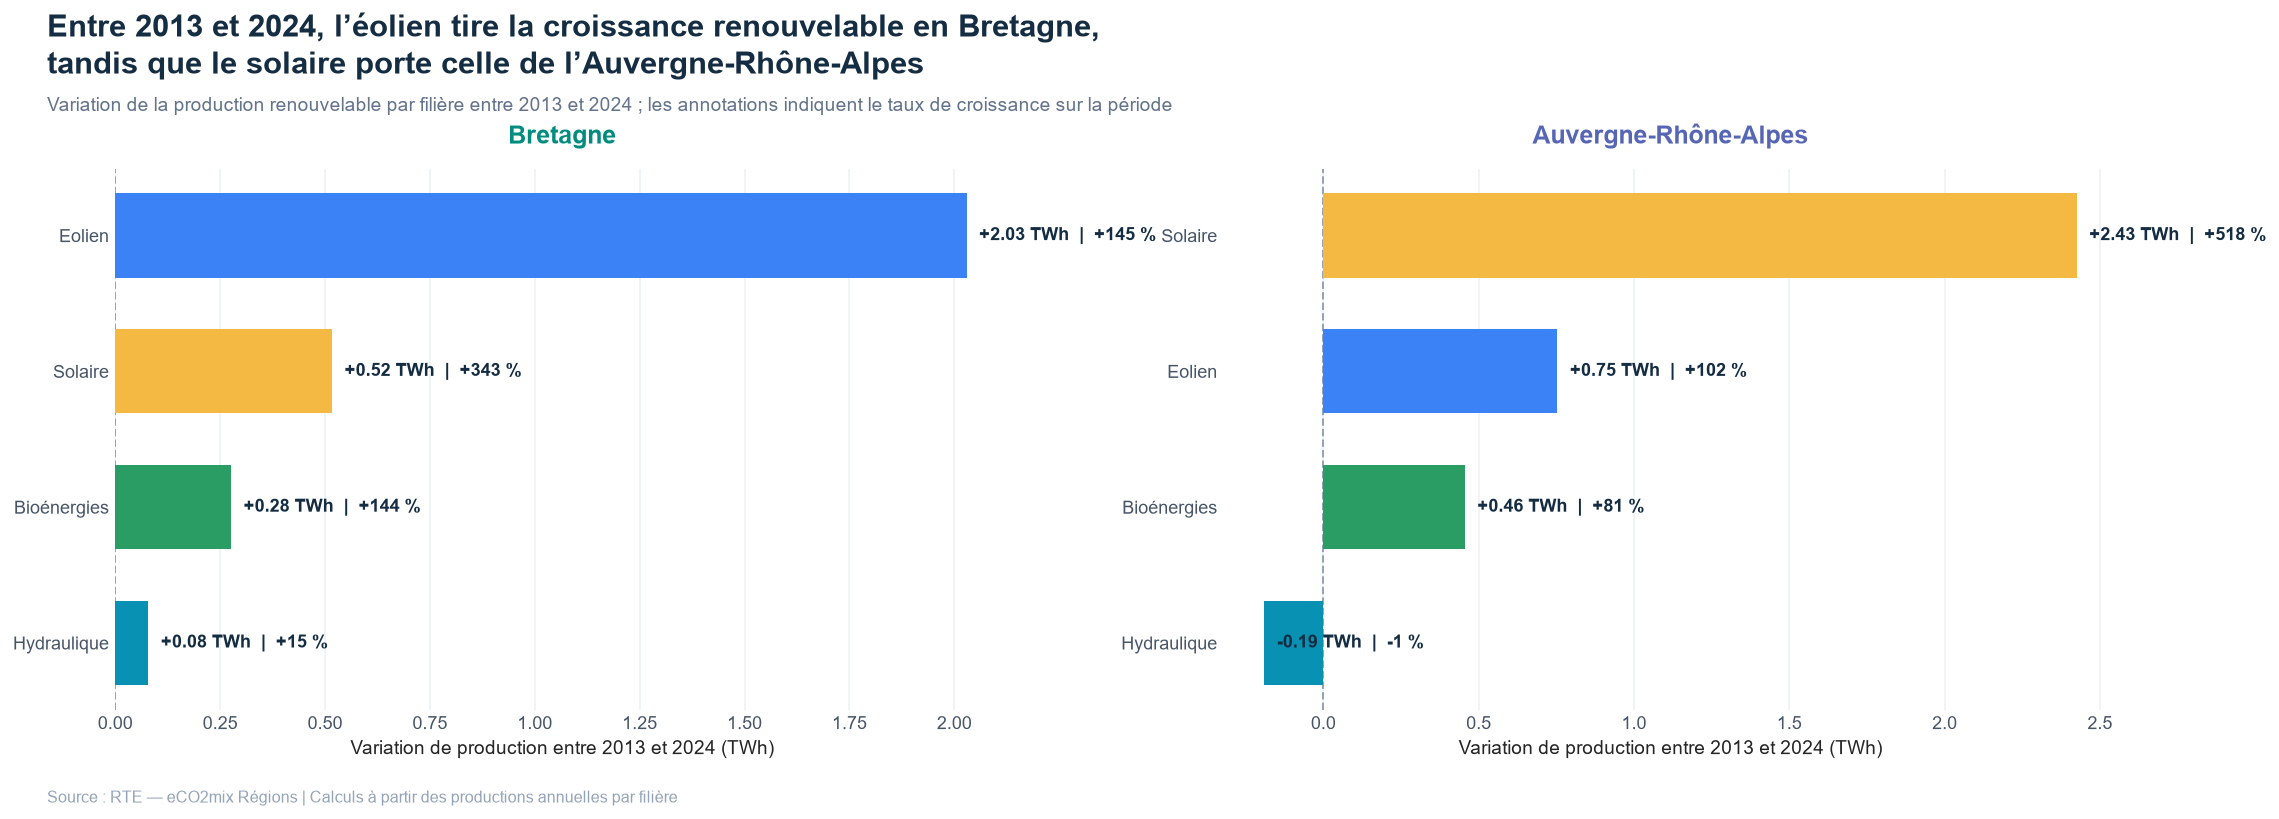

In [268]:
# ============================================================
# 1. PREPARATION
# ============================================================

plot_df = renouvelable_df.copy()

# On retire le nucléaire pour cette question
plot_df = plot_df.query("Filière != 'Nucléaire'").copy()

# Ordre des filières
filieres_order = ["Eolien", "Solaire", "Hydraulique", "Bioénergies"]

plot_df["Filière"] = pd.Categorical(
    plot_df["Filière"], categories=filieres_order, ordered=True
)

plot_df = plot_df.sort_values(["Périmètre", "Variation_TWh"], ascending=[True, True])

filiere_colors = {
     "Eolien": "#3B82F6",
    "Solaire": "#F4B942",
    "Hydraulique": "#0891B2",
    "Bioénergies": "#2A9D65",
}

regions = ["Bretagne", "Auvergne-Rhône-Alpes"]

# ============================================================
# 2. FIGURE
# ============================================================

sns.set_theme(style="white")

fig, ax = plt.subplots(1, 2, figsize=(17.5, 6.5), sharex=False, dpi=130)

fig.patch.set_facecolor("white")

region_title_colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}

for i, region in enumerate(regions):
    data = (
        plot_df.loc[plot_df["Périmètre"] == region]
        .sort_values("Variation_TWh", ascending=True)
        .copy()
    )

    colors = [filiere_colors[f] for f in data["Filière"]]

    ax[i].barh(
        data["Filière"],
        data["Variation_TWh"],
        color=colors,
        height=0.62,
        edgecolor="none",
        zorder=3,
    )

    # annotations : variation TWh + croissance %
    for y, (_, row) in enumerate(data.iterrows()):
        croissance = row["Croissance_%"]
        texte_pct = "n.d." if pd.isna(croissance) else f"{croissance:+.0f} %"

        ax[i].annotate(
            f"{row['Variation_TWh']:+.2f} TWh  |  {texte_pct}",
            xy=(row["Variation_TWh"], y),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            ha="left",
            fontsize=10,
            color="#152D42",
            fontweight="bold",
        )

    ax[i].axvline(0, color="#94A3B8", lw=1.1, linestyle="--", zorder=1)

    ax[i].set_title(
        region,
        fontsize=14,
        fontweight="bold",
        color=region_title_colors[region],
        pad=14,
    )

    ax[i].set_xlabel("Variation de production entre 2013 et 2024 (TWh)", fontsize=10.5)
    ax[i].set_ylabel("")
    ax[i].grid(axis="x", color="#E2E8F0", alpha=0.55)
    ax[i].grid(axis="y", visible=False)
    ax[i].tick_params(axis="both", labelsize=10, length=0, colors="#475569")
    ax[i].set_axisbelow(True)

    sns.despine(ax=ax[i], left=True, bottom=True)

# ============================================================
# 3. TITRE ET SOUS-TITRE
# ============================================================

fig.text(
    0.07,
    0.965,
    "Entre 2013 et 2024, l’éolien tire la croissance renouvelable en Bretagne,",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.07,
    0.92,
    "tandis que le solaire porte celle de l’Auvergne-Rhône-Alpes",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.07,
    0.865,
    "Variation de la production renouvelable par filière entre 2013 et 2024 ; "
    "les annotations indiquent le taux de croissance sur la période",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# ============================================================
# 4. SOURCE
# ============================================================

fig.text(
    0.07,
    0.03,
    "Source : RTE — eCO2mix Régions | Calculs à partir des productions annuelles par filière",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.78,
    bottom=0.14,
    wspace=0.24,
)

fig.savefig(
    "figures/05_evolution_production_renouvelable.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


Entre 2013 et 2024, la production d’électricité renouvelable progresse dans les deux régions, mais selon des dynamiques différentes.
En **Bretagne**, la hausse est principalement portée par l’éolien, dont la production **augmente de 2,03 TWh**, loin devant le solaire (+0,52 TWh), les bioénergies (+0,28 TWh) et l’hydraulique (+0,08 TWh).
En **Auvergne-Rhône-Alpes**, la progression repose surtout sur le **solaire**, en hausse de 2,43 TWh, tandis que l’éolien (+0,75 TWh) et les bioénergies (+0,46 TWh) contribuent plus modestement. L’hydraulique y demeure globalement stable, avec un léger **recul de 0,19 TWh**.
Ces résultats montrent que la transition renouvelable ne repose pas sur les mêmes leviers territoriaux : **l’éolien structure davantage la progression bretonne, alors que le solaire apparaît comme le principal moteur de croissance en Auvergne-Rhône-Alpes.**

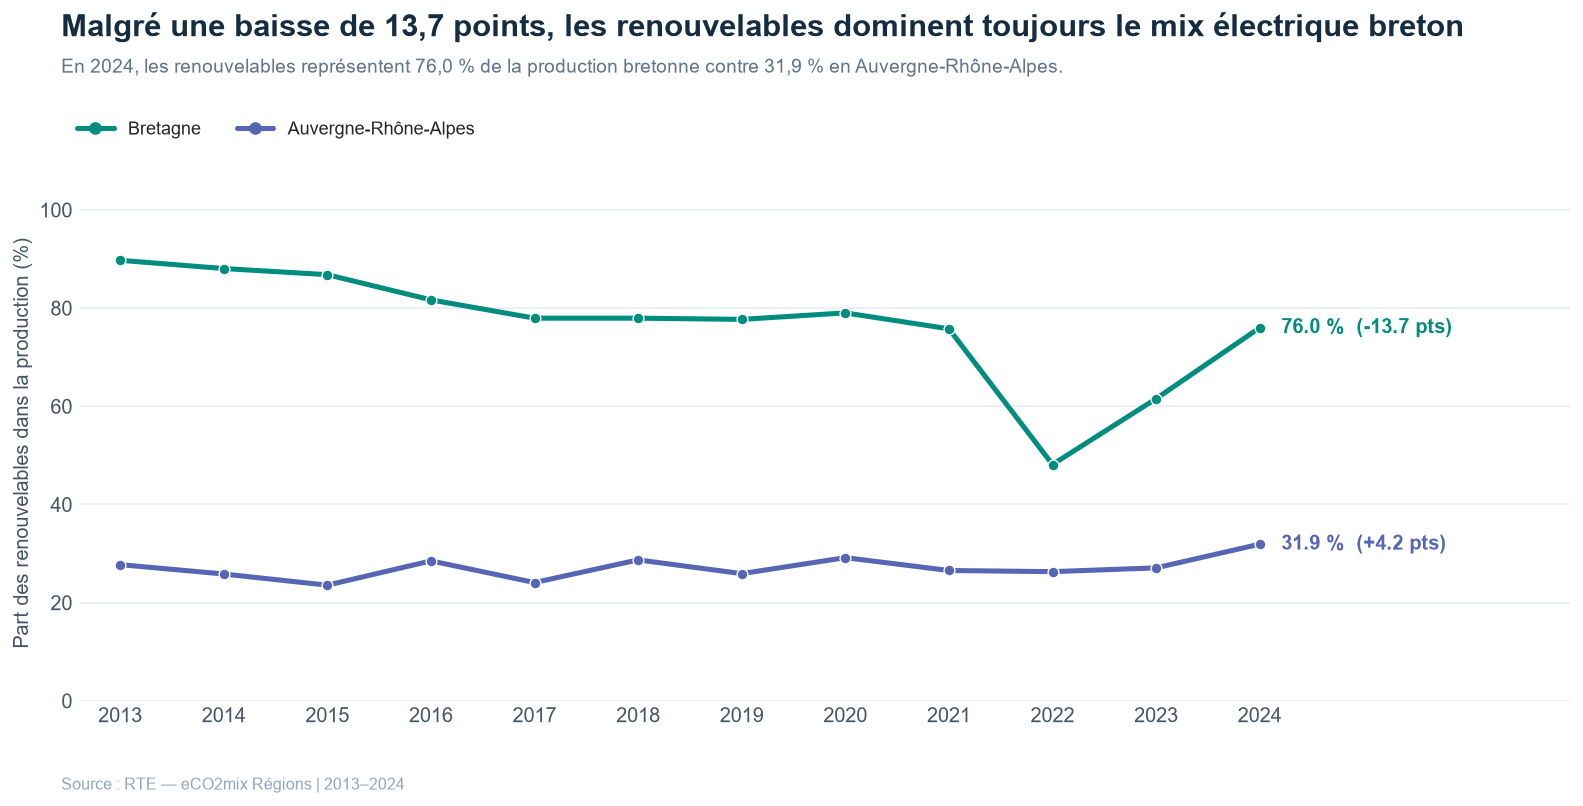

In [269]:
data = resume_annuel.reset_index().sort_values(["Périmètre", "Annee"])

col = "Part_Renouvelable_Production_%"

colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}


fig, ax = plt.subplots(figsize=(13.5, 6.5), dpi=130)
fig.patch.set_facecolor("white")

sns.lineplot(
    data=data,
    x="Annee",
    y=col,
    hue="Périmètre",
    hue_order=list(colors),
    palette=colors,
    marker="o",
    markersize=6,
    linewidth=2.8,
    errorbar=None,
    legend=False,
    ax=ax,
)

# Annotations des valeurs finales et évolutions
for region, color in colors.items():
    region_data = data.loc[data["Périmètre"] == region]

    debut = region_data.loc[region_data["Annee"] == 2013, col].iloc[0]

    fin = region_data.loc[region_data["Annee"] == 2024, col].iloc[0]

    variation = fin - debut

    ax.annotate(
        f"{fin:.1f} %  ({variation:+.1f} pts)",
        xy=(2024, fin),
        xytext=(12, 0),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color=color,
        va="center",
    )

# Axes
ax.set_xlim(2012.6, 2027)
ax.set_ylim(0, 105)

ax.set_xticks(range(2013, 2025))
ax.set_xlabel("")
ax.set_ylabel(
    "Part des renouvelables dans la production (%)",
    fontsize=11,
    color="#475569",
)

ax.grid(axis="y", color="#E2E8F0", alpha=0.7)
ax.tick_params(axis="both", length=0, colors="#475569")
sns.despine(left=True, bottom=True)

# Titre provisoire
fig.text(
    0.09,
    0.965,
    "Malgré une baisse de 13,7 points, les renouvelables dominent toujours le mix électrique breton",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.91,
    "En 2024, les renouvelables représentent 76,0 % de la production bretonne contre 31,9 % en Auvergne-Rhône-Alpes.",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# Légende

handles = [
    Line2D([0], [0], color=color, marker="o", linewidth=2.8, label=region)
    for region, color in colors.items()
]

fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.09, 0.855),
    ncol=2,
    frameon=False,
    fontsize=10,
)

fig.text(
    0.09,
    0.045,
    "Source : RTE — eCO2mix Régions | 2013–2024",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.10,
    right=0.95,
    top=0.76,
    bottom=0.15,
)

fig.savefig(
    "figures/06_Place_renouvelables_mix_electrique.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


In [270]:
# resume_renouvelable = resume_annuel.loc[:, ["Renouvelables_GWh", "Production_TWh"]]
# resume_renouvelable = resume_renouvelable.reset_index().copy()
# resume_renouvelable["Renouvelables_TWh"] = resume_renouvelable["Renouvelables_GWh"].div(1000)
# resume_renouvelable = resume_renouvelable.groupby(["Périmètre"])[
#     ["Production_TWh", "Renouvelables_TWh"]
# ].agg("sum")

# resume_renouvelable["Perc"] = (
#     resume_renouvelable["Renouvelables_TWh"]
#     .div(resume_renouvelable["Production_TWh"])
#     .mul(100)
# )

# resume_renouvelable


# data.groupby("Périmètre")["Part_Renouvelable_Production_%"].mean()

La Bretagne conserve, sur l'ensemble de la période 2013–2024, une **part d'énergies renouvelables dans son mix de production nettement supérieure** à celle de l'Auvergne-Rhône-Alpes.

Cependant, leurs trajectoires divergent : en Bretagne, cette part recule de **13,7 points**, pour atteindre **76,0 % en 2024**, tandis qu'elle progresse légèrement en Auvergne-Rhône-Alpes (**+4,2 points**), pour atteindre **31,9 %**.

Cette diminution de la part renouvelable bretonne ne traduit toutefois pas une baisse de sa production renouvelable en volume. Elle s'explique notamment par l'évolution des autres filières, avec une forte hausse de la production thermique en 2022.

Sur l'ensemble de la période, les énergies renouvelables représentent **73,18 % de la production électrique cumulée bretonne**, contre **27,12 % en Auvergne-Rhône-Alpes**.

### **Q7. Dans quelle mesure la production renouvelable locale permet-elle de couvrir la consommation électrique des deux régions ?**

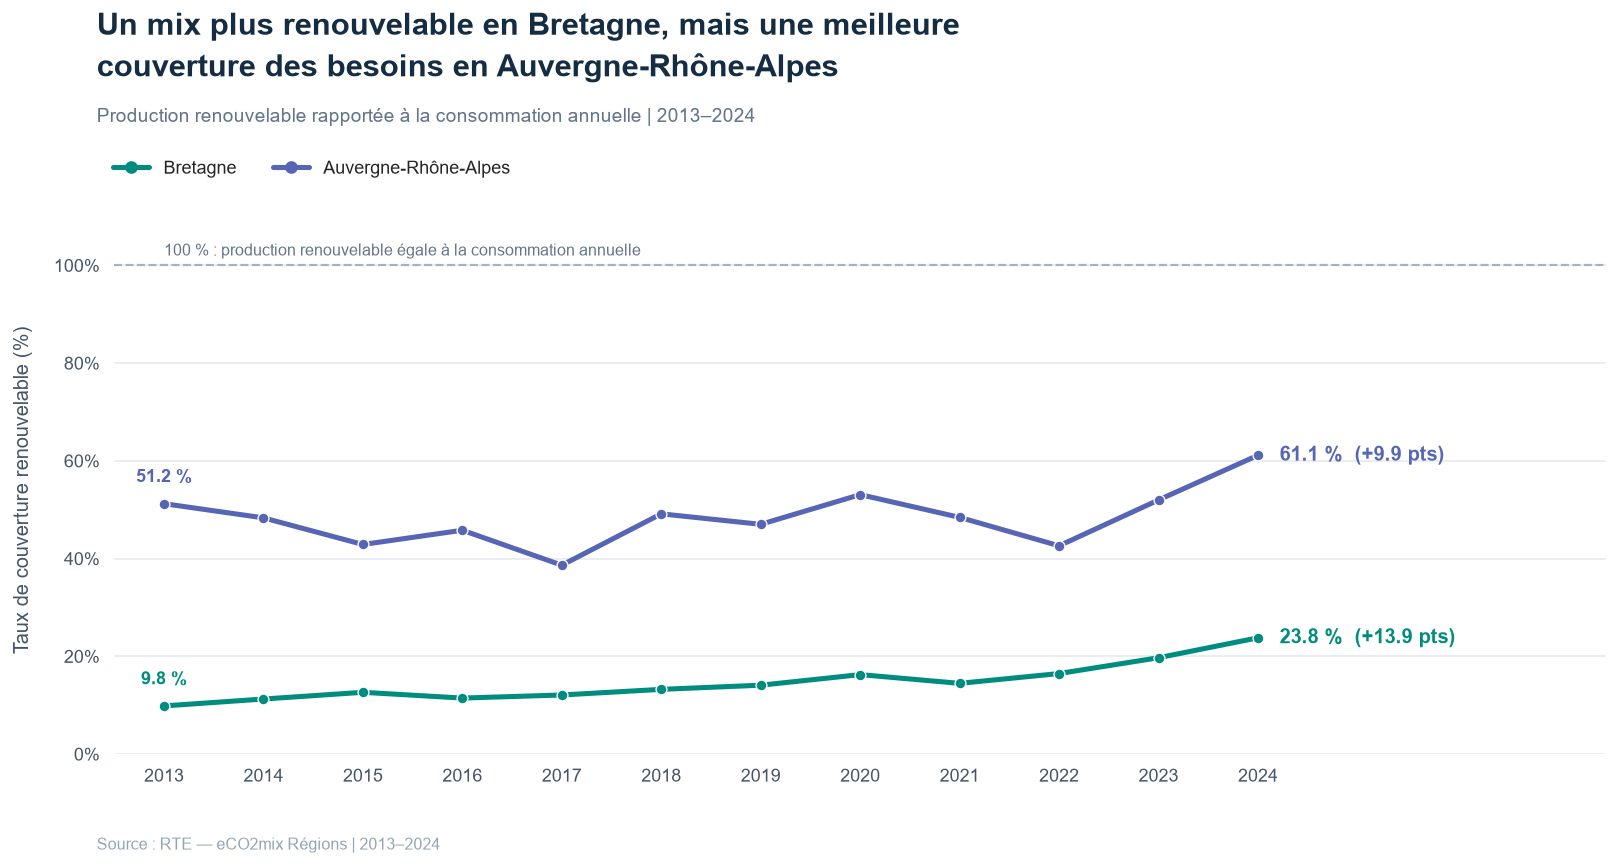

In [271]:
colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}

# Préparation
data = resume_annuel.reset_index().copy()
data = data.sort_values(["Périmètre", "Annee"])
metric = "Couverture_Renouvelable_%"

# Figure
sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(13.5, 7), dpi=130)
fig.patch.set_facecolor("white")

sns.lineplot(
    data=data,
    x="Annee",
    y=metric,
    hue="Périmètre",
    hue_order=list(colors),
    palette=colors,
    marker="o",
    markersize=6,
    linewidth=2.8,
    errorbar=None,
    legend=False,
    ax=ax,
)

# Seuil d'équivalence annuelle
ax.axhline(
    100,
    color="#94A3B8",
    linewidth=1.2,
    linestyle="--",
    alpha=0.8,
)

ax.text(
    2013,
    102,
    "100 % : production renouvelable égale à la consommation annuelle",
    fontsize=9,
    color="#64748B",
)

# Annotations 2013 et 2024
for region, color in colors.items():
    subset = data.loc[data["Périmètre"] == region]

    debut = subset.loc[subset["Annee"] == 2013, metric].iloc[0]
    fin = subset.loc[subset["Annee"] == 2024, metric].iloc[0]

    variation = fin - debut

    ax.annotate(
        f"{debut:.1f} %",
        xy=(2013, debut),
        xytext=(0, 12),
        textcoords="offset points",
        color=color,
        fontsize=10,
        fontweight="bold",
        ha="center",
    )

    ax.annotate(
        f"{fin:.1f} %  ({variation:+.1f} pts)",
        xy=(2024, fin),
        xytext=(12, 0),
        textcoords="offset points",
        color=color,
        fontsize=11,
        fontweight="bold",
        va="center",
    )

# Axes
ax.set_xlim(2012.5, 2027.5)
ax.set_ylim(0, 108)

ax.set_xticks(range(2013, 2025))
ax.set_xlabel("")
ax.set_ylabel(
    "Taux de couverture renouvelable (%)",
    fontsize=11,
    color="#475569",
    labelpad=12,
)

ax.yaxis.set_major_formatter(PercentFormatter(100))

ax.grid(axis="y", color="#E2E8F0", alpha=0.8)
ax.grid(axis="x", visible=False)

ax.tick_params(
    axis="both",
    labelsize=10,
    colors="#475569",
    length=0,
    pad=8,
)

sns.despine(ax=ax, left=True, bottom=True)

# Titre
fig.text(
    0.09,
    0.965,
    "Un mix plus renouvelable en Bretagne, mais une meilleure",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.92,
    "couverture des besoins en Auvergne-Rhône-Alpes",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

# Sous-titre
fig.text(
    0.09,
    0.86,
    "Production renouvelable rapportée à la consommation annuelle | 2013–2024",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# Légende
handles = [
    Line2D(
        [0],
        [0],
        color=color,
        marker="o",
        linewidth=2.8,
        markersize=6,
        label=region,
    )
    for region, color in colors.items()
]

fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.09, 0.82),
    ncol=2,
    frameon=False,
    fontsize=10,
)

# Source
fig.text(
    0.09,
    0.045,
    "Source : RTE — eCO2mix Régions | 2013–2024",
    fontsize=9,
    color="#94A3B8",
)


fig.savefig(
    fname="figures/07_couverture_renouvelable.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.subplots_adjust(
    left=0.10,
    right=0.95,
    top=0.73,
    bottom=0.15,
)

plt.show()


In [272]:
resume_comparatif = (
    data.groupby("Périmètre")
    .agg(
        Couverture_Renouvelable_Moyenne=("Couverture_Renouvelable_%", "mean"),
        Part_Renouvelable_Moyenne=("Part_Renouvelable_Production_%", "mean"),
    )
    .round(2)
)

display(resume_comparatif)


,Couverture_Renouvelable_Moyenne,Part_Renouvelable_Moyenne
Périmètre,,
Auvergne-Rhône-Alpes,48.35,27.12
Bretagne,14.6,76.7


**Un mix majoritairement renouvelable ne garantit pas une forte couverture des besoins électriques.**

Entre 2013 et 2024, les énergies renouvelables représentent en moyenne **76,7 % de la production électrique annuelle bretonne**, contre **27,1 % en Auvergne-Rhône-Alpes**.

Pourtant, le rapport entre production renouvelable et consommation annuelle est nettement supérieur en Auvergne-Rhône-Alpes (**48,35 % en moyenne**, contre **14,6 % en Bretagne**).

Cette différence s'explique principalement par les volumes de production : bien que l'Auvergne-Rhône-Alpes consomme en moyenne près de trois fois plus d'électricité que la Bretagne, elle produit également **près de dix fois plus d'électricité d'origine renouvelable**, selon les calculs réalisés.

Ainsi, **la composition du mix électrique ne suffit pas à évaluer la capacité d'une région à couvrir ses besoins** : les volumes de production doivent également être rapportés à la consommation régionale.

## **Axe 4. Production locale et échanges électriques**

### **Q8. Dans quelle mesure la production électrique totale couvre-t-elle les besoins de chaque région ?(Zoom 2024)**

In [273]:
data = (
    resume_annuel.reset_index()
    .query("Annee == 2024")[
        [
            "Périmètre",
            "Consommation_Totale",
            "Production_Totale",
            "Renouvelables_Total",
        ]
    ]
    .copy()
)

data["Taux_couverture_prod"] = (
    data["Production_Totale"].div(data["Consommation_Totale"]).mul(100)
)

data["Taux_couverture_renouvelable"] = (
    data["Renouvelables_Total"].div(data["Consommation_Totale"]).mul(100)
)

display(
    data[
        [
            "Périmètre",
            "Taux_couverture_prod",
            "Taux_couverture_renouvelable",
        ]
    ].round(2)
)


,Périmètre,Taux_couverture_prod,Taux_couverture_renouvelable
22,Auvergne-Rhône-Alpes,191.56,61.13
23,Bretagne,31.29,23.78


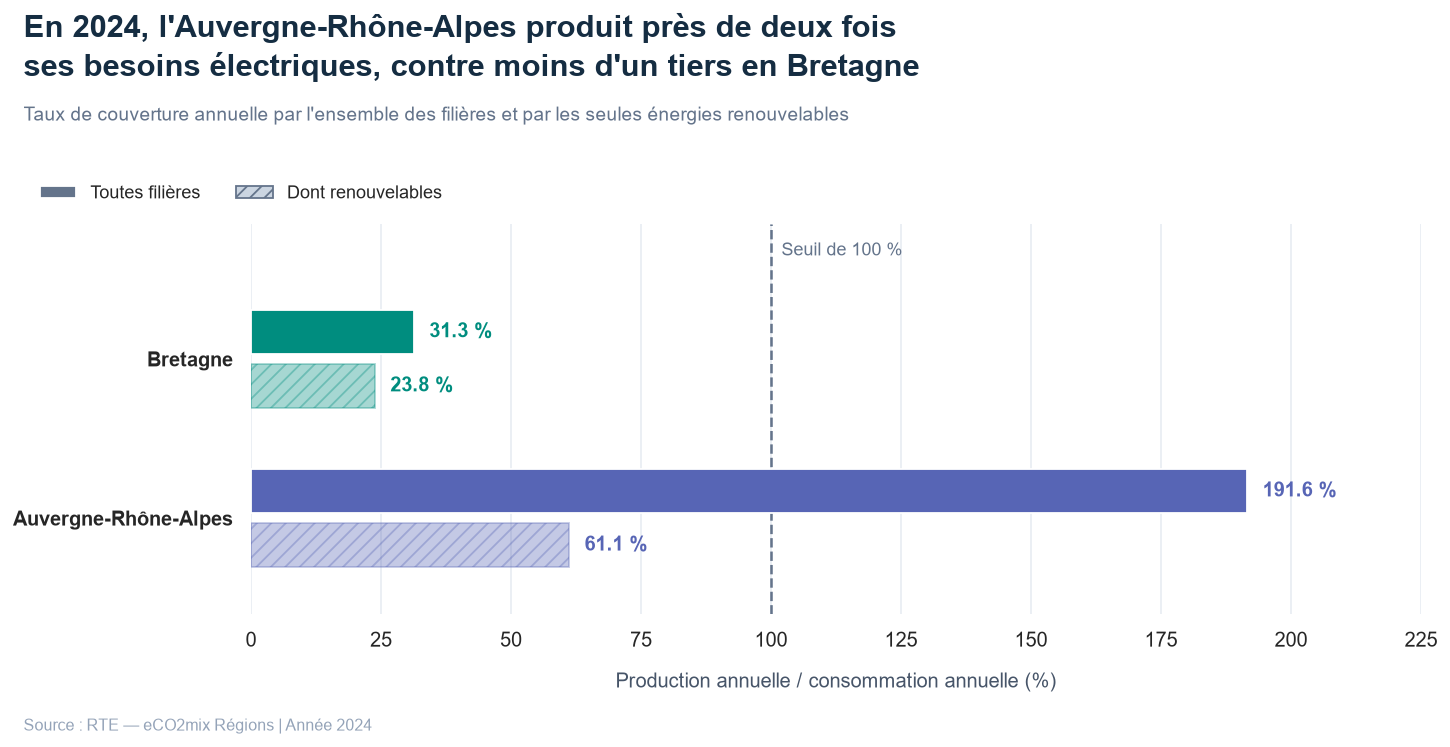

In [274]:
import matplotlib.patches as mpatches

colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}

regions = list(colors)
data_plot = data.set_index("Périmètre").loc[regions]

fig, ax = plt.subplots(figsize=(12.5, 6), dpi=130)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y = np.array([1, 0])
hauteur = 0.28

# Couverture totale
for i, region in enumerate(regions):
    color = colors[region]

    total = float(data_plot.loc[region, "Taux_couverture_prod"])
    renouvelable = float(data_plot.loc[region, "Taux_couverture_renouvelable"])

    ax.barh(
        y[i] + 0.17,
        total,
        height=hauteur,
        color=color,
        zorder=3,
    )

    # Renouvelables : sous-ensemble de la production totale
    ax.barh(
        y[i] - 0.17,
        renouvelable,
        height=hauteur,
        color=color,
        alpha=0.35,
        edgecolor=color,
        linewidth=1,
        hatch="///",
        zorder=3,
    )

    ax.text(
        total + 3,
        y[i] + 0.17,
        f"{total:.1f} %",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=color,
    )

    ax.text(
        renouvelable + 3,
        y[i] - 0.17,
        f"{renouvelable:.1f} %",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=color,
    )

# Référence : production = consommation
ax.axvline(
    100,
    color="#64748B",
    linestyle="--",
    linewidth=1.4,
    zorder=2,
)

ax.text(
    102,
    1.65,
    "Seuil de 100 %",
    fontsize=10,
    color="#64748B",
)

# Axes
ax.set_yticks(y)
ax.set_yticklabels(regions, fontsize=11, fontweight="bold")
ax.set_xlim(0, 225)
ax.set_ylim(-0.6, 1.85)

ax.set_xlabel(
    "Production annuelle / consommation annuelle (%)",
    fontsize=11,
    labelpad=12,
    color="#475569",
)

ax.grid(axis="x", color="#E2E8F0", alpha=0.75)
ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, pad=10)
sns.despine(ax=ax, left=True, bottom=True)

# Titre
fig.text(
    0.08,
    0.96,
    "En 2024, l'Auvergne-Rhône-Alpes produit près de deux fois",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.08,
    0.91,
    "ses besoins électriques, contre moins d'un tiers en Bretagne",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.08,
    0.84,
    "Taux de couverture annuelle par l'ensemble des filières "
    "et par les seules énergies renouvelables",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

# Légende
handles = [
    mpatches.Patch(
        facecolor="#64748B",
        label="Toutes filières",
    ),
    mpatches.Patch(
        facecolor="#CBD5E1",
        edgecolor="#64748B",
        hatch="///",
        label="Dont renouvelables",
    ),
]

fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.08, 0.76),
    ncol=2,
    frameon=False,
    fontsize=10,
)

# Source
fig.text(
    0.08,
    0.04,
    "Source : RTE — eCO2mix Régions | Année 2024",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.22,
    right=0.94,
    top=0.69,
    bottom=0.19,
)

fig.savefig(
    fname="figures/08_couverture_consomation_renouvelable_autres.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


En 2024, les deux régions présentent des bilans électriques annuels fortement contrastés. **La production locale bretonne ne représente que 31,3 % de sa consommation**, tandis que l'Auvergne-Rhône-Alpes produit l'équivalent de **191,6 % de ses besoins électriques**.

Cette situation met en évidence un **déficit de production en Bretagne et un excédent en Auvergne-Rhône-Alpes** à l'échelle annuelle, suggérant des positions opposées dans les échanges d'électricité entre territoires.

### **Q9. Comment les échanges physiques nets ont-ils évolué entre 2013 et 2024 ?**

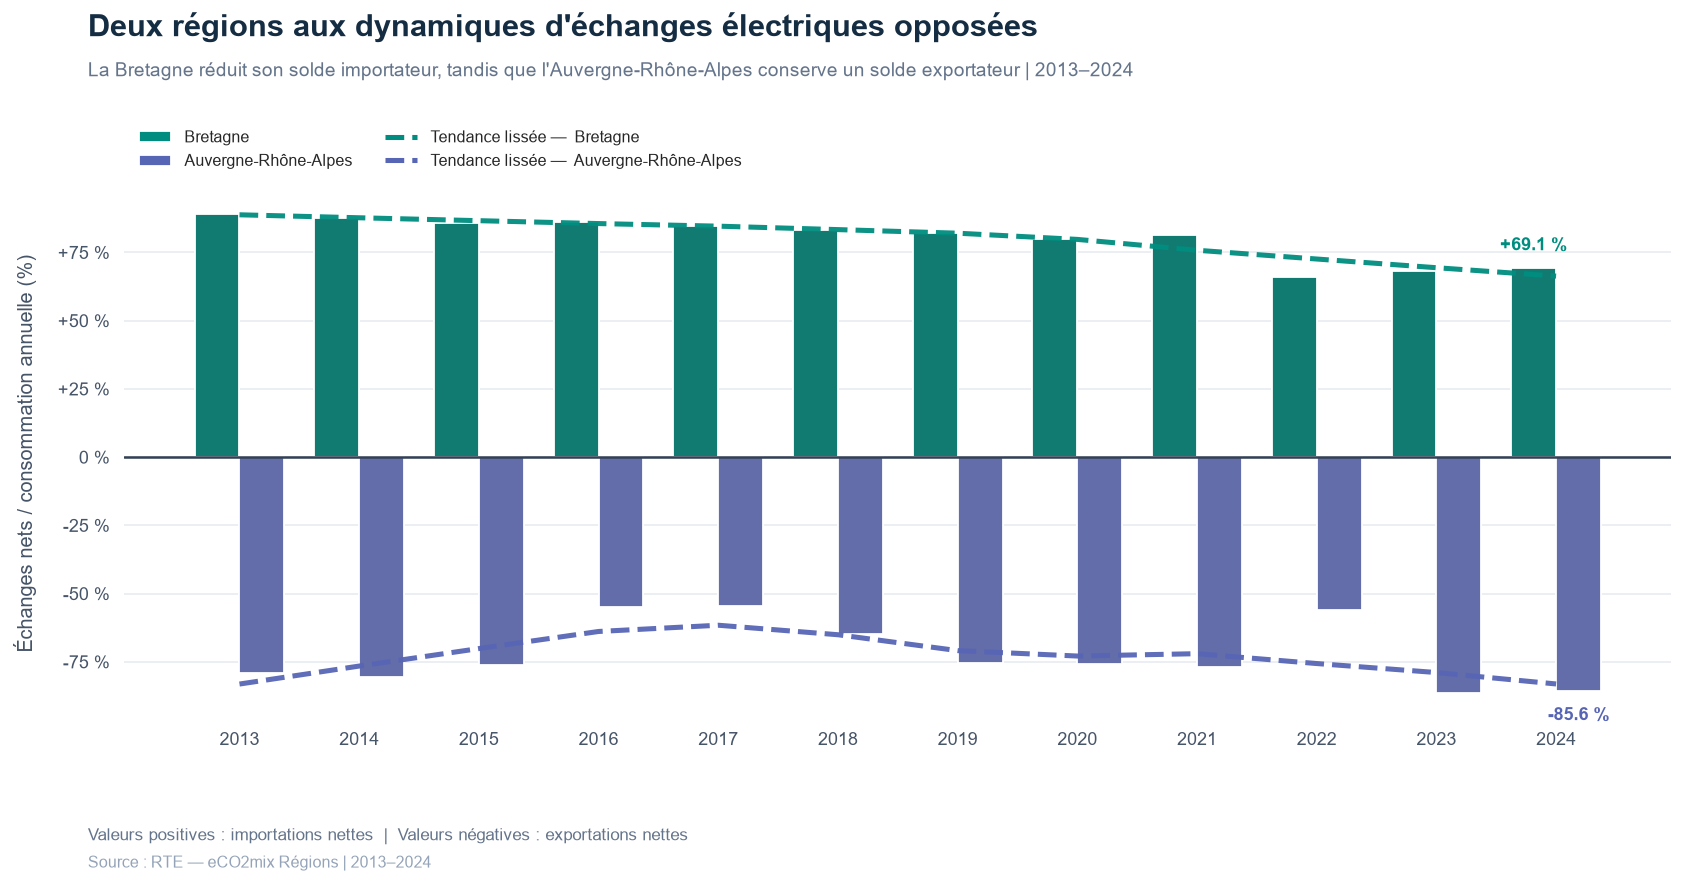

In [275]:


colors = {
    "Bretagne": "#008D7F",
    "Auvergne-Rhône-Alpes": "#5765B5",
}

df = resume_annuel_prop.reset_index().sort_values(["Annee", "Périmètre"]).copy()

metric = "Echanges_sur_Consommation_%"
df[metric] = df[metric].astype("float64")

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(14, 7), dpi=130)
fig.patch.set_facecolor("white")

# Barres divergentes
sns.barplot(
    data=df,
    x="Annee",
    y=metric,
    hue="Périmètre",
    hue_order=list(colors),
    palette=colors,
    errorbar=None,
    ax=ax,
    width=0.75,
)

# Ligne centrale
ax.axhline(
    0,
    color="#334155",
    linewidth=1.4,
    zorder=4,
)

# Annotations des valeurs 2024
for region, container in zip(colors, ax.containers):
    barre = container.patches[-1]
    valeur = barre.get_height()

    ax.annotate(
        f"{valeur:+.1f} %",
        xy=(
            barre.get_x() + barre.get_width() / 2,
            valeur,
        ),
        xytext=(0, 8 if valeur >= 0 else -9),
        textcoords="offset points",
        ha="center",
        va="bottom" if valeur >= 0 else "top",
        fontsize=10,
        fontweight="bold",
        color=colors[region],
    )

# Axes
ax.set_xlabel("")
ax.set_ylabel(
    "Échanges nets / consommation annuelle (%)",
    fontsize=11,
    color="#475569",
    labelpad=12,
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:+.0f} %" if x != 0 else "0 %")
)

ax.grid(
    axis="y",
    color="#E2E8F0",
    alpha=0.75,
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="both",
    labelsize=10,
    length=0,
    pad=8,
    colors="#475569",
)

sns.despine(ax=ax, left=True, bottom=True)

# Légende
ax.legend(
    title="",
    loc="upper left",
    bbox_to_anchor=(0, 1.04),
    ncol=2,
    frameon=False,
    fontsize=10,
)


fig.text(
    0.09,
    0.965,
    "Deux régions aux dynamiques d'échanges électriques opposées",
    fontsize=17,
    fontweight="bold",
    color="#152D42",
    va="top",
)

fig.text(
    0.09,
    0.91,
    "La Bretagne réduit son solde importateur, tandis que l'Auvergne-Rhône-Alpes conserve un solde exportateur | 2013–2024",
    fontsize=10.5,
    color="#64748B",
    va="top",
)

fig.text(
    0.09,
    0.055,
    "Valeurs positives : importations nettes  |  "
    "Valeurs négatives : exportations nettes",
    fontsize=9.5,
    color="#64748B",
)

fig.text(
    0.09,
    0.025,
    "Source : RTE — eCO2mix Régions | 2013–2024",
    fontsize=9,
    color="#94A3B8",
)

fig.subplots_adjust(
    left=0.11,
    right=0.96,
    top=0.77,
    bottom=0.19,
)



# ======================================
# Courbes de tendance LOWESS
# ======================================

annees = sorted(df["Annee"].unique())
positions_annees = {annee: i for i, annee in enumerate(annees)}

for region, color in colors.items():

    data_region = (
        df.loc[df["Périmètre"] == region]
        .sort_values("Annee")
        .dropna(subset=[metric])
    )

    x = data_region["Annee"].to_numpy(dtype=float)
    y = data_region[metric].to_numpy(dtype=float)

    smoothed = lowess(
        endog=y,
        exog=x,
        frac=0.65,
        it=0,
        return_sorted=True,
    )

    positions = [
        positions_annees[int(annee)]
        for annee in smoothed[:, 0]
    ]

    ax.plot(
        positions,
        smoothed[:, 1],
        color=color,
        linewidth=2.8,
        linestyle="--",
        alpha=0.95,
        zorder=6,
    )

# ======================================
# Légende personnalisée
# ======================================

handles = [
    Patch(
        facecolor=color,
        label=region,
    )
    for region, color in colors.items()
]

handles += [
    Line2D(
        [0], [0],
        color=color,
        linewidth=2.8,
        linestyle="--",
        label=f"Tendance lissée —  {region}",
    )
    for region, color in colors.items()
]

ax.legend(
    handles=handles,
    title="",
    loc="upper left",
    bbox_to_anchor=(0, 1.14),
    ncol=2,
    frameon=False,
    fontsize=9,
)

fig.savefig(
    fname="figures/09_evolution_echange_phys.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.show()


Entre 2013 et 2024, **la Bretagne réduit de 22,5 % le poids relatif de ses importations nettes**, qui passent d'environ 89,2 % à 69,1 % de sa consommation annuelle. Malgré cette diminution, la région demeure fortement dépendante des apports électriques extérieurs.

À l'inverse, **l'Auvergne-Rhône-Alpes conserve une position exportatrice nette** sur l'ensemble de la période, avec un solde d'exportations représentant en moyenne 72,2 % de sa consommation annuelle, et atteignant 85,6 % en 2024.

Ces évolutions confirment les contrastes observés entre les deux régions : **une Bretagne dont la production locale reste inférieure aux besoins, face à une Auvergne-Rhône-Alpes structurellement excédentaire à l'échelle annuelle.**

In [276]:
resume_annuel_prop.groupby("Périmètre")["Echanges_sur_Consommation_%"].mean()

Périmètre
Auvergne-Rhône-Alpes      -72.225
Bretagne                80.283333
Name: Echanges_sur_Consommation_%, dtype: Float64

In [277]:
bretagne_prop_resume = resume_annuel_prop.reset_index().query("Périmètre == 'Bretagne' and Annee  in [2013 , 2024]").loc[: , ['Annee' , 'Echanges_sur_Consommation_%']].copy()
bretagne_prop_resume["Echanges_sur_Consommation_%"].pct_change().mul(100)

1          <NA>
23   -22.533632
Name: Echanges_sur_Consommation_%, dtype: Float64

## Conclusion générale

L'analyse comparative des profils électriques de la Bretagne et de l'Auvergne-Rhône-Alpes entre 2013 et 2024 met en évidence deux modèles régionaux fortement contrastés, notamment en matière de production, de consommation et de composition du mix électrique. Malgré une **augmentation de 170 % de sa production électrique** sur la période étudiée, la Bretagne conserve un niveau de production nettement inférieur à celui de l'Auvergne-Rhône-Alpes, qui produit **17,6 fois plus d'électricité en 2024**, alors que sa consommation annuelle est, en moyenne, seulement **2,94 fois supérieure** à celle de la Bretagne.

Cette différence se retrouve également dans la composition de leur mix électrique. La Bretagne présente un mix de production relativement diversifié, principalement dominé par **l'éolien et le thermique**, qui représentent ensemble **71,47 % de sa production cumulée entre 2013 et 2024**. L'éolien constitue le principal moteur de la croissance des énergies renouvelables, avec une augmentation de **2,03 TWh** sur la période. À l'inverse, l'Auvergne-Rhône-Alpes présente un mix fortement concentré sur **le nucléaire et l'hydraulique**, qui totalisent **95,36 % de sa production électrique cumulée**. Parmi les énergies renouvelables, c'est toutefois le solaire qui enregistre la plus forte progression en volume, avec une augmentation de **2,43 TWh** entre 2013 et 2024.

Ces différences de production se traduisent par des situations contrastées en matière de couverture des besoins électriques. En 2024, **l'Auvergne-Rhône-Alpes produit l'équivalent de 191,6 % de sa consommation annuelle**, contre seulement **31,3 % pour la Bretagne**. Pourtant, la production bretonne est composée à **76 % d'énergies renouvelables**, contre **31,9 % en Auvergne-Rhône-Alpes**. Ce contraste se reflète également dans les échanges physiques : la Bretagne demeure importatrice nette, avec un solde représentant **69,1 % de sa consommation en 2024**, tandis que l'Auvergne-Rhône-Alpes conserve une position exportatrice nette, équivalente à **85,6 % de sa consommation**.

**En définitive, la part des énergies renouvelables dans le mix électrique ne suffit pas, à elle seule, à caractériser la situation électrique d'une région.** Une analyse complète nécessite de considérer conjointement les volumes de production, les besoins de consommation, la composition du mix et les échanges physiques nets. C'est cette approche qui permet de mieux comprendre les évolutions des profils électriques régionaux et les différences de couverture des besoins.

In [278]:
output_dir = PROJECT_DIR / "data" / "gold"
output_dir.mkdir(exist_ok=True, parents=True)
resume_annuel_prop.to_csv(output_dir / "resume_annuel_prop.csv" , index='drop')
resume_annuel.reset_index().to_csv(output_dir / "resume_annuel_prop.csv" ,index='drop')


## Annexe

In [279]:
### Annexe
from scipy.stats import ttest_rel

df = rte_data.copy()

df["Date"] = df["datetime"].dt.date
df["Heure"] = df["datetime"].dt.hour
df["Mois"] = df["datetime"].dt.month

# Mois hivernaux
hiver = df[df["Mois"].isin([12, 1, 2])].copy()

# Moyenne journalière
moyenne_jour = (
    hiver.groupby(["Périmètre", "Date"])["Consommation"].mean().rename("Moyenne_Jour")
)

# Moyenne matinale : 7 h inclus à 11 h exclu
moyenne_matin = (
    hiver[hiver["Heure"].between(7, 10)]
    .groupby(["Périmètre", "Date"])["Consommation"]
    .mean()
    .rename("Moyenne_Matin")
)

comparaison = pd.concat([moyenne_jour, moyenne_matin], axis=1).dropna()

comparaison["Indice_Matin"] = (
    comparaison["Moyenne_Matin"] / comparaison["Moyenne_Jour"] * 100
)

display(comparaison.head())

data_test = (
    comparaison["Indice_Matin"]
    .unstack("Périmètre")[["Bretagne", "Auvergne-Rhône-Alpes"]]
    .dropna()
)

stat, p_value = ttest_rel(
    data_test["Bretagne"], data_test["Auvergne-Rhône-Alpes"], alternative="greater"
)

print(f"Statistique t : {stat:.3f}")
print(f"P-value : {p_value:.4f}")
print(
    "Différence moyenne :",
    round((data_test["Bretagne"] - data_test["Auvergne-Rhône-Alpes"]).mean(), 2),
    "points d'indice",
)

differences = data_test["Bretagne"] - data_test["Auvergne-Rhône-Alpes"]

print(differences.describe())

# Autocorrélation des différences à un jour d'intervalle
print("Autocorrélation lag 1 :", differences.autocorr(lag=1))


Moyenne_Jour  Moyenne_Matin  Indice_Matin
Périmètre            Date                                                 
Auvergne-Rhône-Alpes 2013-01-01   7560.829787       6822.625     90.236458
                     2013-01-02       8700.75       8787.625    100.998477
                     2013-01-03   9367.083333         9809.0    104.717762
                     2013-01-04   9133.604167         9580.0    104.887401
                     2013-01-05     8283.0625        8082.75     97.581661

Statistique t : 25.209
P-value : 0.0000
Différence moyenne : 2.58 points d'indice
count       1083.0
mean      2.579033
std       3.366791
min      -7.391913
25%       0.370243
50%       2.410388
75%       4.810009
max      11.982346
dtype: Float64
Autocorrélation lag 1 : 0.19480205024008748
